## Layer1 Market Environment Research

### 1. ライブラリ読込

In [1]:
import os
import datetime as dt

from dotenv import load_dotenv
from pathlib import Path

import json
import time
from urllib.parse import urljoin, urlencode
import requests

import numpy as np
import pandas as pd

import plotly
import plotly.graph_objs as go
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt

from Modules.utility import Utility
from Modules.show_plot import ShowPlot
from Modules.request_api_v2 import RequestApi
from Modules.get_market_data import GetMarketData
from Modules.stock_prices_and_market_data import ClassStockPricesMarketData
from Modules.financial import Financial
from Modules.pdf_url_to_markdown import PDFUrlToMarkdown
from Modules.webpage_to_markdown import WebpageToMarkdown
from Modules.compute_fibonacci_extension import ComputeFibonacciExtension

### 2. パラメータ設定

In [2]:
# FRED API key for accessing Federal Reserve Economic Data
FRED_API_KEY = os.getenv("FRED_API_KEY")
# Output directory for storing downloaded data
API_BASE_URL = os.getenv("API_BASE_URL", "http://localhost:8000")
request_api = RequestApi(API_BASE_URL)
fred_url = "https://api.stlouisfed.org/fred/series/observations"
get_market_data = GetMarketData(Path('/workspace/data'))
utility = Utility()
stock_prices_market_data = ClassStockPricesMarketData()
financial = Financial()
# URLからPDFをダウンロードしてMarkdownに変換するクラスのインスタンスを作成
pdf_to_md = PDFUrlToMarkdown()
# WEBページをMarkdownに変換する関数
webpage_to_markdown = WebpageToMarkdown()
# Fibonacciエクステンションを計算するクラスのインスタンスを作成
fibonacci_extension = ComputeFibonacciExtension()

In [3]:
# Date range for fetching API s
start = '2010-01-01'
end = dt.datetime.now().strftime('%Y-%m-%d')
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
frequency = "d"
aggregation_method = "avg"

#### Utility and Functions

In [4]:
def get_fred_timeseries_data(
    observation_start: str,
    observation_end: str,
    series_mapping: dict[str, str] | None = None,
    frequency: str | None = None,
    aggregation_method: str | None = None,
) -> dict[str, pd.DataFrame]:
    observation_start = observation_start
    observation_end = observation_end
    base_fred_params = {
        "api_key": FRED_API_KEY,
        "file_type": "json",
        "observation_start": observation_start,
        "observation_end": observation_end,
        "frequency": frequency or "m",
        "aggregation_method": aggregation_method or "avg",
    }
    fred_dfs = {}
    for series_id, series_name in series_mapping.items():
        fred_params = base_fred_params.copy()
        fred_params["series_id"] = series_id
        fred_res = requests.get(fred_url, params=fred_params)
        fred_df = pd.DataFrame(fred_res.json()["observations"]).assign(**{
            "date": lambda df: pd.to_datetime(df["date"]),
            "value": lambda df: pd.to_numeric(df["value"], errors="coerce"),
            "interest_rate_type": series_name,
        })
        fred_dfs[series_name] = fred_df
        time.sleep(5)
        
    return fred_dfs

In [5]:
def delete_column(df):
    df.drop(columns=['realtime_start'], inplace=True)
    df.drop(columns=['realtime_end'], inplace=True)
    df.drop(columns=['interest_rate_type'], inplace=True)
    return df

### 3. FREDデータ取得

#### 3.1 DXY

In [6]:
dxy_df = get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"DEXUSAL": "DXY"},
    frequency=frequency,
    aggregation_method=aggregation_method
)["DXY"]
dxy_df["date"] = pd.to_datetime(dxy_df["date"])
dxy_df = dxy_df.set_index("date")
dxy_df = delete_column(dxy_df)
dxy_df.tail()

,value
date,
2026-10-05,0.6969
2026-10-06,0.6984
2026-10-07,0.6962
2026-10-08,0.6949
2026-10-09,0.6979


#### 3.2 US10Y

In [7]:
us10y_df = get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"DGS10": "us_treasury_10y"},
    frequency=frequency,
    aggregation_method=aggregation_method
)["us_treasury_10y"]
us10y_df["date"] = pd.to_datetime(us10y_df["date"])
us10y_df = us10y_df.set_index("date")
us10y_df = delete_column(us10y_df)
us10y_df.tail()

,value
date,
2026-10-09,5.24
2026-10-12,NaN
2026-10-13,5.21
2026-10-14,5.19
2026-10-15,5.10


#### 3.3 Real Yield

In [8]:
real_yield_df = get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"DFII10": "real_10y"},
    frequency=frequency,
    aggregation_method=aggregation_method
)["real_10y"]
real_yield_df["date"] = pd.to_datetime(real_yield_df["date"])
real_yield_df = real_yield_df.set_index("date")
real_yield_df = delete_column(real_yield_df)
real_yield_df.tail()

,value
date,
2026-10-09,2.91
2026-10-12,NaN
2026-10-13,2.88
2026-10-14,2.84
2026-10-15,2.78


#### 3.4 Credit Spread

In [9]:
credit_spread_df = get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"BAMLH0A0HYM2": "credit_spread"},
    frequency=frequency,
    aggregation_method=aggregation_method
)["credit_spread"]
credit_spread_df["date"] = pd.to_datetime(credit_spread_df["date"])
credit_spread_df = credit_spread_df.set_index("date")
credit_spread_df = delete_column(credit_spread_df)
credit_spread_df.tail()

,value
date,
2026-10-09,3.11
2026-10-12,3.11
2026-10-13,3.16
2026-10-14,3.25
2026-10-15,3.23


### 4. Yahoo Financeデータ取得

#### 4.1 SPY

In [10]:
spy_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="SPY",
    market=None,
    series_name="SPY"
))
spy_df.tail()

取得件数: 4431


,value
date,
2026-10-12,778.780029
2026-10-13,777.340027
2026-10-14,774.919983
2026-10-15,766.250000
2026-10-16,773.239990


#### 4.2 VIX

In [11]:
vix_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="^VIX",
    market=None,
    series_name="VIX"
))
vix_df.tail()

取得件数: 4433


,value
date,
2026-10-12,15.390000
2026-10-13,15.610000
2026-10-14,15.170000
2026-10-15,17.549999
2026-10-16,16.020000


#### 4.3 Copper

In [12]:
copper_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="HG=F",
    market=None,
    series_name="COPPER"
))
copper_df.tail()

取得件数: 4431


,value
date,
2026-10-12,6.6895
2026-10-13,6.6775
2026-10-14,6.6750
2026-10-15,6.5770
2026-10-16,6.5740


#### 4.4 HYG

In [13]:
hyg_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="HYG",
    market=None,
    series_name="HYG"
))
hyg_df.tail()

取得件数: 4431


,value
date,
2026-10-12,77.209999
2026-10-13,77.230003
2026-10-14,76.849998
2026-10-15,76.870003
2026-10-16,77.050003


#### 4.5 IEF

In [14]:
ief_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="IEF",
    market=None,
    series_name="IEF"
))
ief_df.tail()

取得件数: 4254


,value
date,
2026-10-12,89.330002
2026-10-13,89.650002
2026-10-14,89.010002
2026-10-15,90.599998
2026-10-16,90.150002


#### 4.6 DBC

In [15]:
dbc_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="DBC",
    market=None,
    series_name="DBC"
))
dbc_df.tail()

取得件数: 4254


,value
date,
2026-10-12,33.299999
2026-10-13,33.279999
2026-10-14,33.410000
2026-10-15,33.240002
2026-10-16,33.299999


### 5. データ統合

In [16]:
# ============================================================
# 5. データ統合
# ============================================================
# 各データを共通フォーマットへ変換
df_list = [
    dxy_df.rename(columns={'value': "DXY"}),
    copper_df.rename(columns={'value': "Copper"}),
    vix_df.rename(columns={'value' : "VIX"}),
    hyg_df.rename(columns={'value': "HYG"}),
    ief_df.rename(columns={'value': "IEF"}),
    us10y_df.rename(columns={'value': "US10Y"}),
    real_yield_df.rename(columns={'value': "RealYield"}),
    spy_df.rename(columns={'value': "SPY"}),
    dbc_df.rename(columns={'value': "DBC"})
]

# 日付で外部結合
market_df = pd.concat(df_list, axis=1, join="outer")

# 日付順にソート
market_df = market_df.sort_index()

# 重複日付除去
market_df = market_df[~market_df.index.duplicated(keep="first")]

# 欠損補完
market_df = market_df.ffill()

# 全列欠損行は削除
market_df = market_df.dropna(how="all")

# 確認
print("=" * 60)
print("Market Data Shape")
print(market_df.shape)

print("\nColumns")
print(market_df.columns.tolist())

print("\nHead")
display(market_df.head())

print("\nTail")
display(market_df.tail())

Market Data Shape
(4589, 9)

Columns
['DXY', 'Copper', 'VIX', 'HYG', 'IEF', 'US10Y', 'RealYield', 'SPY', 'DBC']

Head


/tmp/ipykernel_26/2235498673.py:18: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  market_df = pd.concat(df_list, axis=1, join="outer")


,DXY,Copper,VIX,HYG,IEF,US10Y,RealYield,SPY,DBC
date,,,,,,,,,
2009-03-09,NaN,1.6830,49.349998,21.804537,NaN,NaN,NaN,49.441109,NaN
2009-03-10,NaN,1.6390,49.680000,21.815023,NaN,NaN,NaN,50.576165,NaN
2009-03-11,NaN,1.6700,43.349998,22.903175,NaN,NaN,NaN,53.115528,NaN
2009-03-12,NaN,1.6100,43.529999,23.004652,NaN,NaN,NaN,52.839018,NaN
2009-03-13,NaN,1.6465,40.990002,23.448970,NaN,NaN,NaN,55.305618,NaN



Tail


,DXY,Copper,VIX,HYG,IEF,US10Y,RealYield,SPY,DBC
date,,,,,,,,,
2026-10-12,0.6979,6.6895,15.390000,77.209999,89.330002,5.24,2.91,778.780029,33.299999
2026-10-13,0.6979,6.6775,15.610000,77.230003,89.650002,5.21,2.88,777.340027,33.279999
2026-10-14,0.6979,6.6750,15.170000,76.849998,89.010002,5.19,2.84,774.919983,33.410000
2026-10-15,0.6979,6.5770,17.549999,76.870003,90.599998,5.10,2.78,766.250000,33.240002
2026-10-16,0.6979,6.5740,16.020000,77.050003,90.150002,5.10,2.78,773.239990,33.299999


In [17]:
print("\nMissing Value Ratio (%)")
display(
    (
        market_df.isna().sum()
        / len(market_df)
        * 100
    ).sort_values(ascending=False)
)


Missing Value Ratio (%)


DXY          4.554369
US10Y        4.554369
RealYield    4.554369
IEF          3.857049
DBC          3.857049
Copper       0.000000
VIX          0.000000
HYG          0.000000
SPY          0.000000
dtype: float64

In [18]:
market_df.isna().sum() / len(market_df) * 100

DXY          4.554369
Copper       0.000000
VIX          0.000000
HYG          0.000000
IEF          3.857049
US10Y        4.554369
RealYield    4.554369
SPY          0.000000
DBC          3.857049
dtype: float64

### 6. 派生特徴量作成

##### 6.1 HYG/IEF

In [19]:
market_df["HYG_IEF"] = (
    market_df["HYG"]
    / market_df["IEF"]
)

##### 6.2 20日変化率

In [20]:
for col in [
    "DXY",
    "Copper",
    "VIX",
    "HYG",
    "IEF",
    "US10Y",
    "RealYield",
    "SPY",
    "DBC",
    "HYG_IEF"
]:
    market_df[f"{col}_Ret20"] = (
        market_df[col]
        .pct_change(20)
    )

##### 6.3 60日変化率

In [21]:
for col in [
    "DXY",
    "Copper",
    "VIX",
    "HYG",
    "IEF",
    "US10Y",
    "RealYield",
    "SPY",
    "DBC",
    "HYG_IEF"
]:
    market_df[f"{col}_Ret60"] = (
        market_df[col]
        .pct_change(60)
    )

##### 6.4 60日Z-score

In [22]:
for col in [
    "DXY",
    "Copper",
    "VIX",
    "HYG",
    "IEF",
    "US10Y",
    "RealYield",
    "SPY",
    "DBC",
    "HYG_IEF"
]:
    rolling_mean = market_df[col].rolling(60).mean()
    rolling_std = market_df[col].rolling(60).std()

    market_df[f"{col}_Z60"] = (
        market_df[col] - rolling_mean
    ) / rolling_std

In [23]:
market_df

,DXY,Copper,VIX,HYG,IEF,US10Y,RealYield,SPY,DBC,HYG_IEF,...,DXY_Z60,Copper_Z60,VIX_Z60,HYG_Z60,IEF_Z60,US10Y_Z60,RealYield_Z60,SPY_Z60,DBC_Z60,HYG_IEF_Z60
date,,,,,,,,,,,,,,,,,,,,,
2009-03-09,NaN,1.6830,49.349998,21.804537,NaN,NaN,NaN,49.441109,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2009-03-10,NaN,1.6390,49.680000,21.815023,NaN,NaN,NaN,50.576165,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2009-03-11,NaN,1.6700,43.349998,22.903175,NaN,NaN,NaN,53.115528,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2009-03-12,NaN,1.6100,43.529999,23.004652,NaN,NaN,NaN,52.839018,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2009-03-13,NaN,1.6465,40.990002,23.448970,NaN,NaN,NaN,55.305618,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-12,0.6979,6.6895,15.390000,77.209999,89.330002,5.24,2.91,778.780029,33.299999,0.864323,...,-1.099898,1.138558,-0.517430,-1.639382,-1.573787,1.600542,1.742208,1.374445,1.326510,1.172814
2026-10-13,0.6979,6.6775,15.610000,77.230003,89.650002,5.21,2.88,777.340027,33.279999,0.861461,...,-1.088499,1.006194,-0.308013,-1.545616,-1.280834,1.417846,1.532977,1.213654,1.269452,0.683581
2026-10-14,0.6979,6.6750,15.170000,76.849998,89.010002,5.19,2.84,774.919983,33.410000,0.863386,...,-1.080155,0.956840,-0.660966,-1.991595,-1.692049,1.285756,1.292852,0.972080,1.306118,0.965364


### 7. データ品質確認

#### 7.1 基本情報

In [24]:
print("=" * 80)
print("Market Data Info")
print("=" * 80)

market_df.info()

Market Data Info
<class 'pandas.DataFrame'>
DatetimeIndex: 4589 entries, 2009-03-09 to 2026-10-16
Data columns (total 40 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   DXY              4380 non-null   float64
 1   Copper           4589 non-null   float64
 2   VIX              4589 non-null   float64
 3   HYG              4589 non-null   float64
 4   IEF              4412 non-null   float64
 5   US10Y            4380 non-null   float64
 6   RealYield        4380 non-null   float64
 7   SPY              4589 non-null   float64
 8   DBC              4412 non-null   float64
 9   HYG_IEF          4412 non-null   float64
 10  DXY_Ret20        4360 non-null   float64
 11  Copper_Ret20     4569 non-null   float64
 12  VIX_Ret20        4569 non-null   float64
 13  HYG_Ret20        4569 non-null   float64
 14  IEF_Ret20        4392 non-null   float64
 15  US10Y_Ret20      4360 non-null   float64
 16  RealYield_Ret20  4360 non-null   flo

#### 7.2 欠損率確認

In [25]:
missing_ratio = (
    market_df.isna().sum()
    / len(market_df)
    * 100
)

display(
    missing_ratio.sort_values(
        ascending=False
    )
)

DXY_Ret60          5.861844
RealYield_Ret60    5.861844
US10Y_Ret60        5.861844
RealYield_Z60      5.840052
US10Y_Z60          5.840052
DXY_Z60            5.840052
IEF_Ret60          5.164524
HYG_IEF_Ret60      5.164524
DBC_Ret60          5.164524
DBC_Z60            5.142733
IEF_Z60            5.142733
HYG_IEF_Z60        5.142733
DXY_Ret20          4.990194
US10Y_Ret20        4.990194
RealYield_Ret20    4.990194
DXY                4.554369
US10Y              4.554369
RealYield          4.554369
IEF_Ret20          4.292874
DBC_Ret20          4.292874
HYG_IEF_Ret20      4.292874
IEF                3.857049
DBC                3.857049
HYG_IEF            3.857049
HYG_Ret60          1.307474
SPY_Ret60          1.307474
VIX_Ret60          1.307474
Copper_Ret60       1.307474
Copper_Z60         1.285683
VIX_Z60            1.285683
HYG_Z60            1.285683
SPY_Z60            1.285683
Copper_Ret20       0.435825
HYG_Ret20          0.435825
SPY_Ret20          0.435825
VIX_Ret20          0

#### 7.3 無限値確認

In [26]:
import numpy as np

inf_count = np.isinf(
    market_df.select_dtypes(
        include=np.number
    )
).sum()

display(inf_count)

DXY                 0
Copper              0
VIX                 0
HYG                 0
IEF                 0
US10Y               0
RealYield           0
SPY                 0
DBC                 0
HYG_IEF             0
DXY_Ret20           0
Copper_Ret20        0
VIX_Ret20           0
HYG_Ret20           0
IEF_Ret20           0
US10Y_Ret20         0
RealYield_Ret20    16
SPY_Ret20           0
DBC_Ret20           0
HYG_IEF_Ret20       0
DXY_Ret60           0
Copper_Ret60        0
VIX_Ret60           0
HYG_Ret60           0
IEF_Ret60           0
US10Y_Ret60         0
RealYield_Ret60    16
SPY_Ret60           0
DBC_Ret60           0
HYG_IEF_Ret60       0
DXY_Z60             0
Copper_Z60          0
VIX_Z60             0
HYG_Z60             0
IEF_Z60             0
US10Y_Z60           0
RealYield_Z60       0
SPY_Z60             0
DBC_Z60             0
HYG_IEF_Z60         0
dtype: int64

#### 7.4 最終欠損除去

In [27]:
market_df.tail()

,DXY,Copper,VIX,HYG,IEF,US10Y,RealYield,SPY,DBC,HYG_IEF,...,DXY_Z60,Copper_Z60,VIX_Z60,HYG_Z60,IEF_Z60,US10Y_Z60,RealYield_Z60,SPY_Z60,DBC_Z60,HYG_IEF_Z60
date,,,,,,,,,,,,,,,,,,,,,
2026-10-12,0.6979,6.6895,15.390000,77.209999,89.330002,5.24,2.91,778.780029,33.299999,0.864323,...,-1.099898,1.138558,-0.517430,-1.639382,-1.573787,1.600542,1.742208,1.374445,1.326510,1.172814
2026-10-13,0.6979,6.6775,15.610000,77.230003,89.650002,5.21,2.88,777.340027,33.279999,0.861461,...,-1.088499,1.006194,-0.308013,-1.545616,-1.280834,1.417846,1.532977,1.213654,1.269452,0.683581
2026-10-14,0.6979,6.6750,15.170000,76.849998,89.010002,5.19,2.84,774.919983,33.410000,0.863386,...,-1.080155,0.956840,-0.660966,-1.991595,-1.692049,1.285756,1.292852,0.972080,1.306118,0.965364
2026-10-15,0.6979,6.5770,17.549999,76.870003,90.599998,5.10,2.78,766.250000,33.240002,0.848455,...,-1.081859,0.141252,1.413388,-1.875070,-0.488249,0.875983,0.974088,0.163578,1.156351,-1.464961
2026-10-16,0.6979,6.5740,16.020000,77.050003,90.150002,5.10,2.78,773.239990,33.299999,0.854687,...,-1.075078,0.082895,0.130699,-1.570971,-0.798880,0.847232,0.942948,0.807195,1.154458,-0.475504


### 8. 目的変数作成

In [28]:
# ============================================================
# 8. 目的変数作成
# ============================================================

TARGET_TICKERS = [
    "XLE",   # Energy
    "XME",   # Metals & Mining
    "GDX",   # Gold Miners
    "SIL",   # Silver Miners
    "COPX",  # Copper Miners
    "URNM"   # Uranium
]

#### 8.1 ETF取得

In [29]:
target_df_list = []

for code in TARGET_TICKERS:
    df = request_api.fetch_stock_timeseries_data(
        code=code,
        market=None,
        start_date=start,
        end_date=end
    )

    df = pd.concat(
        [df["date"], df[["close"]].rename(columns={"close": code})],
        axis=1
    )
    # date列をdatetime型に変換
    df["date"] = pd.to_datetime(df["date"])
    df = df.set_index("date")
    # date列をインデックスに設定
    target_df_list.append(df)

取得件数: 4254
取得件数: 4254
取得件数: 4431
取得件数: 4150
取得件数: 4150
取得件数: 1726


#### 8.2 ETF統合

In [30]:
target_df = pd.concat(
    target_df_list,
    axis=1,
    join="outer"
)
# データフレームを日付順にソートし、欠損値を前方補完
target_df = target_df.sort_index()
target_df = target_df.ffill()
display(target_df.head())
display(target_df.tail())

/tmp/ipykernel_26/4049250586.py:1: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  target_df = pd.concat(


,XLE,XME,GDX,SIL,COPX,URNM
date,,,,,,
2009-03-09,NaN,NaN,28.256081,NaN,NaN,NaN
2009-03-10,NaN,NaN,27.148339,NaN,NaN,NaN
2009-03-11,NaN,NaN,26.031940,NaN,NaN,NaN
2009-03-12,NaN,NaN,27.563738,NaN,NaN,NaN
2009-03-13,NaN,NaN,28.723406,NaN,NaN,NaN


,XLE,XME,GDX,SIL,COPX,URNM
date,,,,,,
2026-10-12,65.849998,105.639999,88.230003,85.809998,85.290001,46.125999
2026-10-13,66.500000,104.660004,89.129997,86.150002,85.129997,45.150002
2026-10-14,67.599998,101.910004,84.949997,81.430000,82.500000,43.770000
2026-10-15,67.900002,99.620003,84.779999,80.959999,79.139999,41.689999
2026-10-16,67.120003,101.459999,86.610001,81.699997,80.949997,43.930000


#### 8.3 将来20営業日リターン

In [31]:
for col in TARGET_TICKERS:

    target_df[f"{col}_Future20D"] = (
        target_df[col]
        .shift(-20)
        .div(target_df[col])
        .sub(1.0)
    )
target_df.head()

,XLE,XME,GDX,SIL,COPX,URNM,XLE_Future20D,XME_Future20D,GDX_Future20D,SIL_Future20D,COPX_Future20D,URNM_Future20D
date,,,,,,,,,,,,
2009-03-09,NaN,NaN,28.256081,NaN,NaN,NaN,NaN,NaN,0.022971,NaN,NaN,NaN
2009-03-10,NaN,NaN,27.148339,NaN,NaN,NaN,NaN,NaN,0.070449,NaN,NaN,NaN
2009-03-11,NaN,NaN,26.031940,NaN,NaN,NaN,NaN,NaN,0.136303,NaN,NaN,NaN
2009-03-12,NaN,NaN,27.563738,NaN,NaN,NaN,NaN,NaN,0.050236,NaN,NaN,NaN
2009-03-13,NaN,NaN,28.723406,NaN,NaN,NaN,NaN,NaN,0.030431,NaN,NaN,NaN


#### 8.4 将来60営業日リターン

In [32]:
for col in TARGET_TICKERS:

    target_df[f"{col}_Future60D"] = (
        target_df[col]
        .shift(-60)
        .div(target_df[col])
        .sub(1.0)
    )
display(target_df.head())

,XLE,XME,GDX,SIL,COPX,URNM,XLE_Future20D,XME_Future20D,GDX_Future20D,SIL_Future20D,COPX_Future20D,URNM_Future20D,XLE_Future60D,XME_Future60D,GDX_Future60D,SIL_Future60D,COPX_Future60D,URNM_Future60D
date,,,,,,,,,,,,,,,,,,
2009-03-09,NaN,NaN,28.256081,NaN,NaN,NaN,NaN,NaN,0.022971,NaN,NaN,NaN,NaN,NaN,0.339663,NaN,NaN,NaN
2009-03-10,NaN,NaN,27.148339,NaN,NaN,NaN,NaN,NaN,0.070449,NaN,NaN,NaN,NaN,NaN,0.362767,NaN,NaN,NaN
2009-03-11,NaN,NaN,26.031940,NaN,NaN,NaN,NaN,NaN,0.136303,NaN,NaN,NaN,NaN,NaN,0.404588,NaN,NaN,NaN
2009-03-12,NaN,NaN,27.563738,NaN,NaN,NaN,NaN,NaN,0.050236,NaN,NaN,NaN,NaN,NaN,0.271586,NaN,NaN,NaN
2009-03-13,NaN,NaN,28.723406,NaN,NaN,NaN,NaN,NaN,0.030431,NaN,NaN,NaN,NaN,NaN,0.267852,NaN,NaN,NaN


#### 8.5 market_dfへ結合

In [33]:
market_df = market_df.join(
    target_df,
    how="left"
)

#### 8.6 最終確認

In [34]:
target_cols = [
    c for c in market_df.columns
    if "Future" in c
]

print(target_cols)

display(
    market_df[target_cols]
    .tail()
)

['XLE_Future20D', 'XME_Future20D', 'GDX_Future20D', 'SIL_Future20D', 'COPX_Future20D', 'URNM_Future20D', 'XLE_Future60D', 'XME_Future60D', 'GDX_Future60D', 'SIL_Future60D', 'COPX_Future60D', 'URNM_Future60D']


,XLE_Future20D,XME_Future20D,GDX_Future20D,SIL_Future20D,COPX_Future20D,URNM_Future20D,XLE_Future60D,XME_Future60D,GDX_Future60D,SIL_Future60D,COPX_Future60D,URNM_Future60D
date,,,,,,,,,,,,
2026-10-12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-10-13,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-10-14,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-10-15,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-10-16,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [35]:
missing_ratio = (
    market_df.isna().sum()
    / len(market_df)
    * 100
)

display(
    missing_ratio.sort_values(
        ascending=False
    )
)

URNM_Future60D     63.695794
URNM_Future20D     62.824145
URNM               62.388320
SIL_Future60D      10.873829
COPX_Future60D     10.873829
SIL_Future20D      10.002179
COPX_Future20D     10.002179
COPX                9.566354
SIL                 9.566354
XLE_Future60D       8.607540
XME_Future60D       8.607540
XME_Future20D       7.735890
XLE_Future20D       7.735890
XME                 7.300065
XLE                 7.300065
DXY_Ret60           5.861844
RealYield_Ret60     5.861844
US10Y_Ret60         5.861844
RealYield_Z60       5.840052
US10Y_Z60           5.840052
DXY_Z60             5.840052
IEF_Ret60           5.164524
DBC_Ret60           5.164524
HYG_IEF_Ret60       5.164524
IEF_Z60             5.142733
HYG_IEF_Z60         5.142733
DBC_Z60             5.142733
DXY_Ret20           4.990194
US10Y_Ret20         4.990194
RealYield_Ret20     4.990194
GDX_Future60D       4.750490
DXY                 4.554369
US10Y               4.554369
RealYield           4.554369
IEF_Ret20     

### 9. 単独指標検証

#### 9.1 検証対象定義

In [36]:
# ============================================================
# 9. 単独指標検証
# ============================================================

FEATURES = [
    "DXY",
    "Copper",
    "VIX",
    "HYG",
    "IEF",
    "HYG_IEF",
    "US10Y",
    "RealYield",
    "SPY",
    "DBC",
]

TARGETS = [
    "XLE_Future20D",
    "XME_Future20D",
    "GDX_Future20D",
    "SIL_Future20D",
    "COPX_Future20D",
    "URNM_Future20D",
]

#### 9.2 相関係数確認

In [37]:
corr_results = []

for feature in FEATURES:

    for target in TARGETS:

        temp = market_df[
            [feature, target]
        ].dropna()

        corr = temp[feature].corr(
            temp[target]
        )

        corr_results.append(
            {
                "Feature": feature,
                "Target": target,
                "Correlation": corr
            }
        )

corr_df = pd.DataFrame(corr_results)

display(
    corr_df.sort_values(
        "Correlation",
        key=lambda x: abs(x),
        ascending=False
    )
)

,Feature,Target,Correlation
17,VIX,URNM_Future20D,0.274492
12,VIX,XLE_Future20D,0.245416
59,DBC,URNM_Future20D,-0.229155
16,VIX,COPX_Future20D,0.228136
13,VIX,XME_Future20D,0.226164
2,DXY,GDX_Future20D,-0.199196
15,VIX,SIL_Future20D,0.194469
14,VIX,GDX_Future20D,0.190673
35,HYG_IEF,URNM_Future20D,-0.180913
29,IEF,URNM_Future20D,0.171875


#### 9.3 20日変化率版

In [38]:
FEATURES_RET20 = [
    c
    for c in market_df.columns
    if c.endswith("_Ret20")
]

corr_results = []

for feature in FEATURES_RET20:

    for target in TARGETS:

        temp = market_df[
            [feature, target]
        ].dropna()

        corr = temp[feature].corr(
            temp[target]
        )

        corr_results.append(
            {
                "Feature": feature,
                "Target": target,
                "Correlation": corr
            }
        )

corr_ret20_df = pd.DataFrame(
    corr_results
)

display(
    corr_ret20_df.sort_values(
        "Correlation",
        key=lambda x: abs(x),
        ascending=False
    ).head(50)
)

/workspace/.venv/lib/python3.12/site-packages/numpy/_core/_methods.py:132: RuntimeWarning: invalid value encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)


,Feature,Target,Correlation
59,HYG_IEF_Ret20,URNM_Future20D,-0.167976
47,SPY_Ret20,URNM_Future20D,-0.163135
56,HYG_IEF_Ret20,GDX_Future20D,-0.145751
23,HYG_Ret20,URNM_Future20D,-0.145699
17,VIX_Ret20,URNM_Future20D,0.144754
44,SPY_Ret20,GDX_Future20D,-0.133843
42,SPY_Ret20,XLE_Future20D,-0.130383
33,US10Y_Ret20,SIL_Future20D,-0.126864
14,VIX_Ret20,GDX_Future20D,0.122245
32,US10Y_Ret20,GDX_Future20D,-0.122037


#### 9.3 20日変化率版

In [39]:
FEATURES_RET20 = [
    c
    for c in market_df.columns
    if c.endswith("_Ret20")
]

corr_results = []

for feature in FEATURES_RET20:

    for target in TARGETS:

        temp = market_df[
            [feature, target]
        ].dropna()

        corr = temp[feature].corr(
            temp[target]
        )

        corr_results.append(
            {
                "Feature": feature,
                "Target": target,
                "Correlation": corr
            }
        )

corr_ret20_df = pd.DataFrame(
    corr_results
)

display(
    corr_ret20_df.sort_values(
        "Correlation",
        key=lambda x: abs(x),
        ascending=False
    ).head(50)
)

/workspace/.venv/lib/python3.12/site-packages/numpy/_core/_methods.py:132: RuntimeWarning: invalid value encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)


,Feature,Target,Correlation
59,HYG_IEF_Ret20,URNM_Future20D,-0.167976
47,SPY_Ret20,URNM_Future20D,-0.163135
56,HYG_IEF_Ret20,GDX_Future20D,-0.145751
23,HYG_Ret20,URNM_Future20D,-0.145699
17,VIX_Ret20,URNM_Future20D,0.144754
44,SPY_Ret20,GDX_Future20D,-0.133843
42,SPY_Ret20,XLE_Future20D,-0.130383
33,US10Y_Ret20,SIL_Future20D,-0.126864
14,VIX_Ret20,GDX_Future20D,0.122245
32,US10Y_Ret20,GDX_Future20D,-0.122037


#### 9.4 ZScore版

In [40]:
FEATURES_Z60 = [
    c
    for c in market_df.columns
    if c.endswith("_Z60")
]

corr_results = []

for feature in FEATURES_Z60:

    for target in TARGETS:

        temp = market_df[
            [feature, target]
        ].dropna()

        corr = temp[feature].corr(
            temp[target]
        )

        corr_results.append(
            {
                "Feature": feature,
                "Target": target,
                "Correlation": corr
            }
        )

corr_z60_df = pd.DataFrame(
    corr_results
)

display(
    corr_z60_df.sort_values(
        "Correlation",
        key=lambda x: abs(x),
        ascending=False
    ).head(50)
)

,Feature,Target,Correlation
43,SPY_Z60,XME_Future20D,-0.164803
44,SPY_Z60,GDX_Future20D,-0.146381
47,SPY_Z60,URNM_Future20D,-0.128430
46,SPY_Z60,COPX_Future20D,-0.128420
42,SPY_Z60,XLE_Future20D,-0.119835
45,SPY_Z60,SIL_Future20D,-0.110297
59,HYG_IEF_Z60,URNM_Future20D,-0.097519
20,HYG_Z60,GDX_Future20D,-0.096071
2,DXY_Z60,GDX_Future20D,-0.086744
56,HYG_IEF_Z60,GDX_Future20D,-0.081122


#### 9.5 散布図可視化

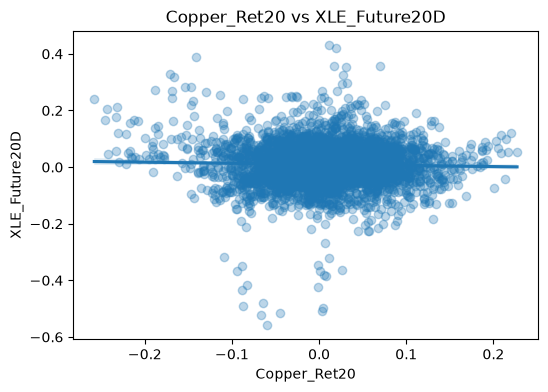

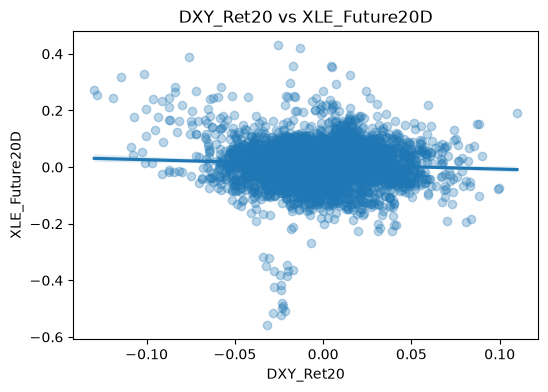

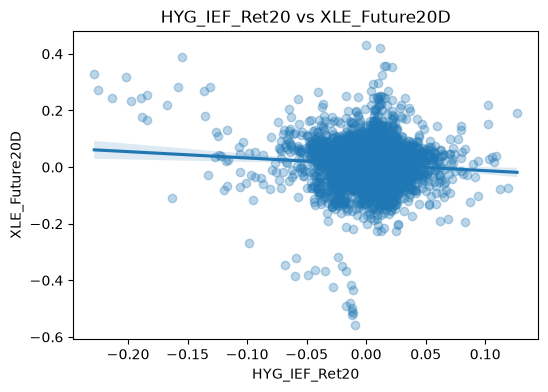

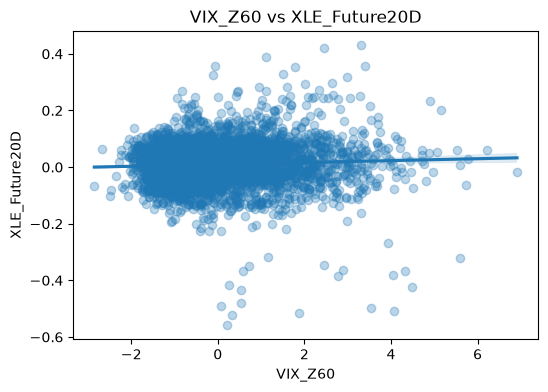

In [41]:
TOP_FEATURES = [
    "Copper_Ret20",
    "DXY_Ret20",
    "HYG_IEF_Ret20",
    "VIX_Z60"
]

TARGET = "XLE_Future20D"

for feature in TOP_FEATURES:

    temp = market_df[
        [feature, TARGET]
    ].dropna()

    plt.figure(figsize=(6, 4))

    sns.regplot(
        data=temp,
        x=feature,
        y=TARGET,
        scatter_kws={"alpha": 0.3}
    )

    plt.title(
        f"{feature} vs {TARGET}"
    )

    # ファイル名にコードと期間を含める
    output_path = output_dir / f"{feature}_{start}_{end}.png"
    # 既存の画像ファイルが存在する場合は削除
    if output_path.exists():
        output_path.unlink()
    # 画像ファイルを保存
    fig = plt.gcf()
    fig.savefig(str(output_path), dpi=300, bbox_inches='tight')

    plt.show()
    plt.close(fig)

### 10. リードラグ分析

#### 10.1 検証対象

In [42]:
# ============================================================
# 10. リードラグ分析
# ============================================================

FEATURES = [
    "DXY_Z60",
    "Copper_Z60",
    "VIX_Z60",
    "HYG_IEF_Z60",
    "US10Y_Z60",
    "DBC_Z60",
]

TARGETS = [
    "XLE_Future20D",
    "XME_Future20D",
    "GDX_Future20D",
    "SIL_Future20D",
    "COPX_Future20D",
    "URNM_Future20D"
]

LAGS = range(-60, 61)

#### 10.2 リードラグ計算

In [43]:
lead_lag_results = []

for feature in FEATURES:

    for target in TARGETS:

        best_lag = None
        best_corr = None

        for lag in LAGS:

            shifted_feature = (
                market_df[feature]
                .shift(lag)
            )

            temp = pd.concat(
                [
                    shifted_feature,
                    market_df[target]
                ],
                axis=1
            ).dropna()

            if len(temp) < 100:
                continue

            corr = temp.iloc[:, 0].corr(
                temp.iloc[:, 1]
            )

            if pd.isna(corr):
                continue

            if (
                best_corr is None
                or abs(corr) > abs(best_corr)
            ):
                best_corr = corr
                best_lag = lag

        lead_lag_results.append(
            {
                "Feature": feature,
                "Target": target,
                "BestLag": best_lag,
                "BestCorr": best_corr
            }
        )

#### 10.3 結果確認

In [44]:
lead_lag_df = pd.DataFrame(
    lead_lag_results
)

display(
    lead_lag_df
    .sort_values(
        "BestCorr",
        key=lambda x: abs(x),
        ascending=False
    )
)

,Feature,Target,BestLag,BestCorr
10,Copper_Z60,COPX_Future20D,-21,0.663096
4,DXY_Z60,COPX_Future20D,-20,0.572874
7,Copper_Z60,XME_Future20D,-21,0.549450
30,DBC_Z60,XLE_Future20D,-21,0.532129
1,DXY_Z60,XME_Future20D,-20,0.500266
34,DBC_Z60,COPX_Future20D,-21,0.490418
18,HYG_IEF_Z60,XLE_Future20D,-20,0.459271
19,HYG_IEF_Z60,XME_Future20D,-21,0.443055
31,DBC_Z60,XME_Future20D,-21,0.440310
5,DXY_Z60,URNM_Future20D,-20,0.421858


#### 10.4 個別可視化

In [45]:
for feature in FEATURES:
    for target in TARGETS:
        # 対象のFeatureとTargetの結果を取得
        result = lead_lag_df[
            (lead_lag_df["Feature"] == feature)
            &
            (lead_lag_df["Target"] == target)
        ]
        # BestLagがNaNの場合はスキップ
        if result["BestLag"].isna().iloc[0]:
            continue
        # BestLagを取得
        best_lag = int(
            result["BestLag"].iloc[0]
        )
        lag_corr = []
        # 各ラグに対する相関を計算
        for lag in LAGS:

            corr = (
                market_df[feature]
                .shift(lag)
                .corr(
                    market_df[target]
                )
            )
            lag_corr.append(corr)
        # 相関の結果をプロット
        plt.figure(figsize=(12, 6))
        plt.plot(
            list(LAGS),
            lag_corr
        )
        plt.axvline(
            best_lag,
            color="red",
            linestyle="--"
        )
        plt.title(
            f"{feature} vs {target}"
        )
        plt.xlabel("Lag")
        plt.ylabel("Correlation")
        plt.grid(True)
        # ファイル名にコードと期間を含める
        output_path = output_dir / f"{feature}_VS_{target}__{start}_{end}.png"
        # 既存の画像ファイルが存在する場合は削除
        if output_path.exists():
            output_path.unlink()
        # 画像ファイルを保存
        fig = plt.gcf()
        fig.savefig(str(output_path), dpi=300, bbox_inches='tight')
        # プロットを閉じる
        #plt.show()
        plt.close(fig)

### 10. リードラグ分析（リーク確認版）

#### 10.1 検証対象

In [46]:
# ============================================================
# 10. リードラグ分析
# Leak Check Version
# ============================================================

FEATURES = [
    "DXY_Z60",
    "Copper_Z60",
    "VIX_Z60",
    "HYG_IEF_Z60",
    "US10Y_Z60",
    "DBC_Z60"
]

TARGETS = [
    "XLE_Future20D",
    "XME_Future20D",
    "GDX_Future20D",
    "SIL_Future20D",
    "COPX_Future20D",
    "URNM_Future20D"
]

# 過去のみ利用
LAGS = range(0, 61)


#### 10.2 リードラグ分析

In [47]:
lead_lag_results = []

for feature in FEATURES:
    for target in TARGETS:

        best_lag = None
        best_corr = None

        for lag in LAGS:

            shifted_feature = (
                market_df[feature]
                .shift(lag)
            )

            temp = pd.concat(
                [
                    shifted_feature.rename(feature),
                    market_df[target]
                ],
                axis=1
            ).dropna()

            if len(temp) < 100:
                continue

            corr = temp[feature].corr(
                temp[target]
            )

            if pd.isna(corr):
                continue

            if (
                best_corr is None
                or abs(corr) > abs(best_corr)
            ):
                best_corr = corr
                best_lag = lag

        lead_lag_results.append(
            {
                "Feature": feature,
                "Target": target,
                "BestLag": best_lag,
                "BestCorr": best_corr
            }
        )

lead_lag_df = pd.DataFrame(
    lead_lag_results
)

#### 10.3 ランキング表示

In [48]:
display(
    lead_lag_df
    .sort_values(
        "BestCorr",
        key=lambda x: abs(x),
        ascending=False
    )
)

,Feature,Target,BestLag,BestCorr
23,HYG_IEF_Z60,URNM_Future20D,22,-0.225008
5,DXY_Z60,URNM_Future20D,29,-0.184831
29,US10Y_Z60,URNM_Future20D,26,-0.173347
35,DBC_Z60,URNM_Future20D,29,-0.158161
17,VIX_Z60,URNM_Future20D,15,0.151811
33,DBC_Z60,SIL_Future20D,44,-0.139672
27,US10Y_Z60,SIL_Future20D,57,-0.137619
21,HYG_IEF_Z60,SIL_Future20D,43,-0.130934
32,DBC_Z60,GDX_Future20D,41,-0.129385
9,Copper_Z60,SIL_Future20D,47,-0.124031


#### 10.4 可視化

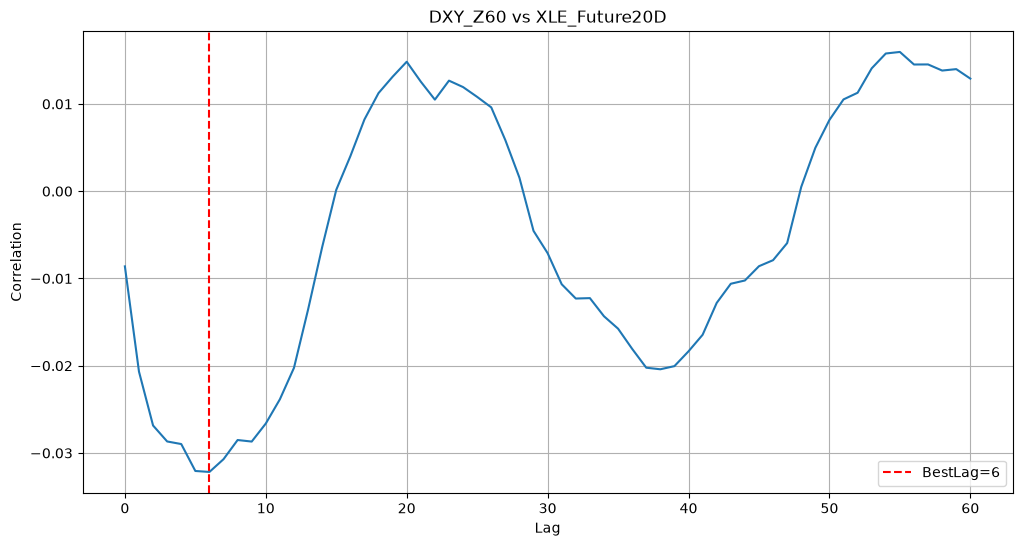

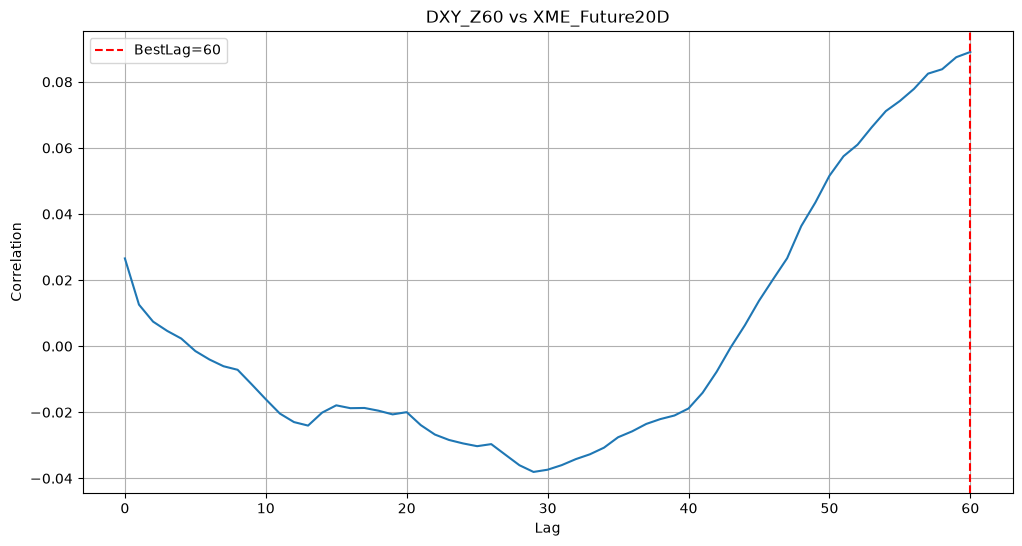

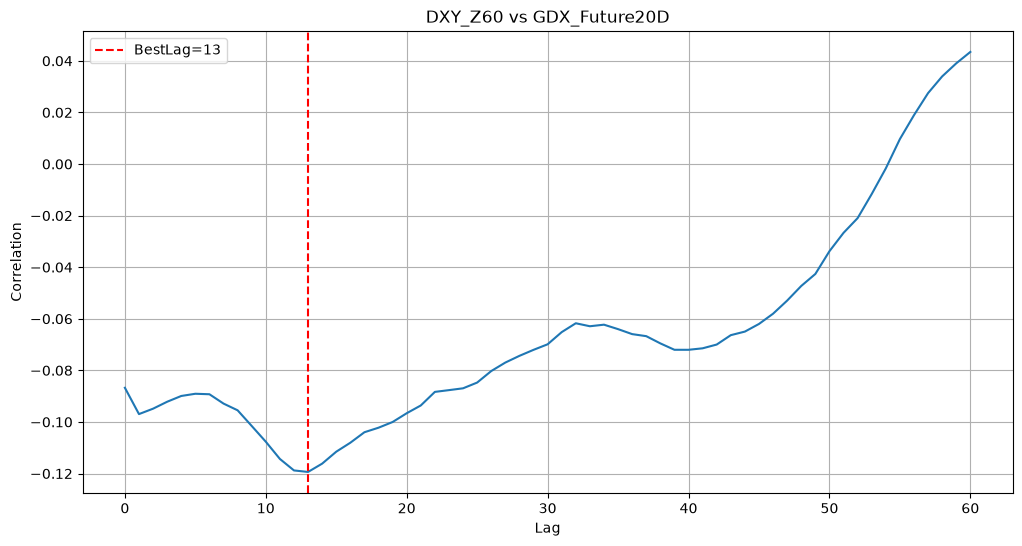

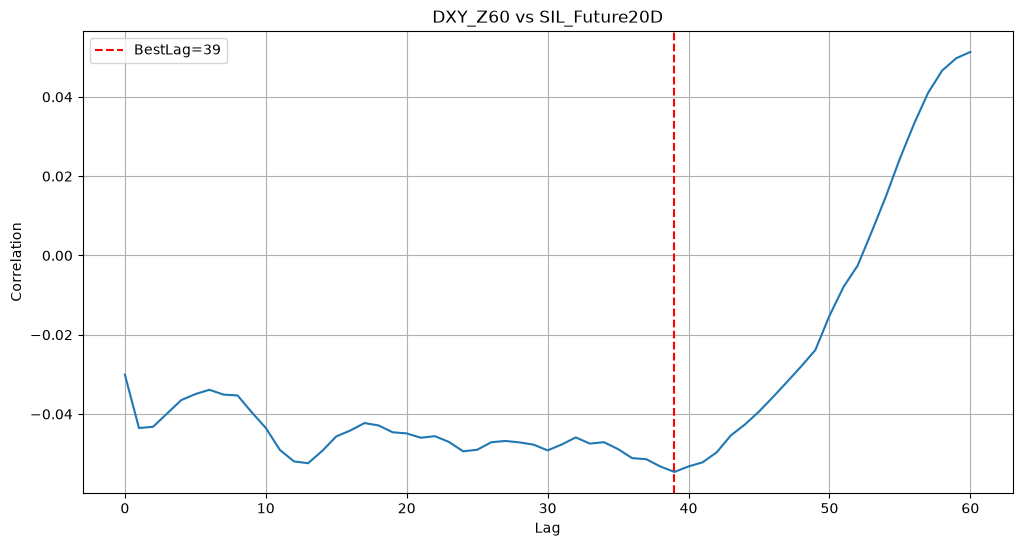

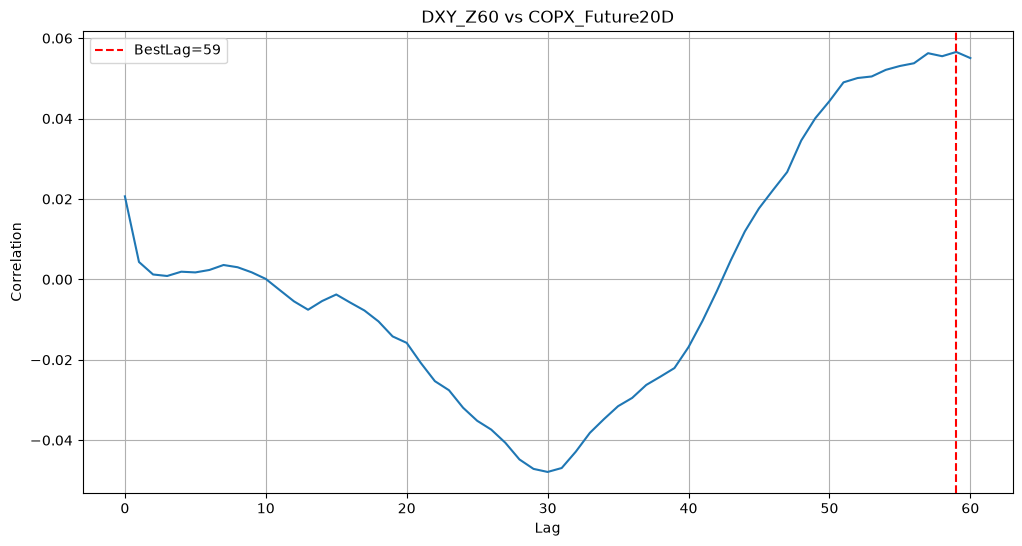

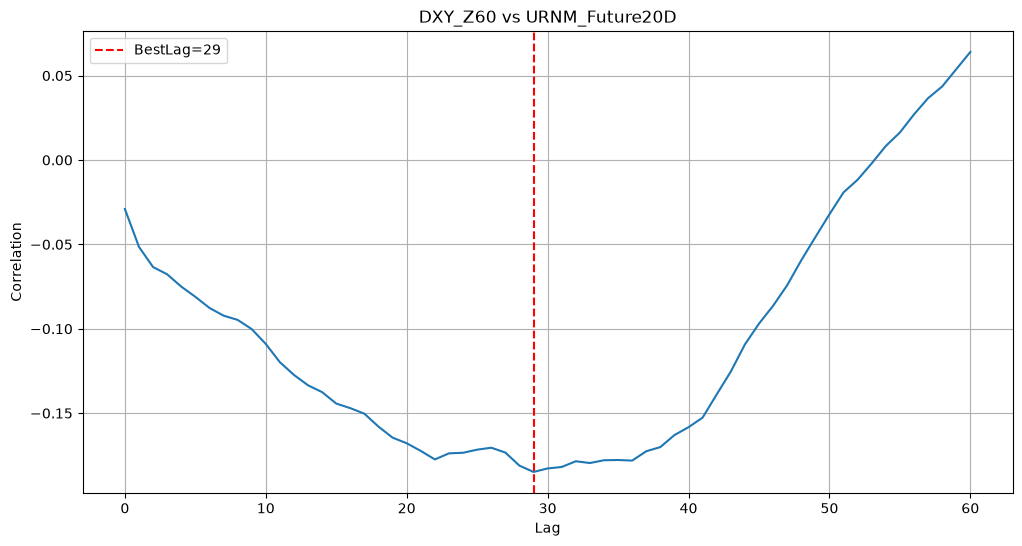

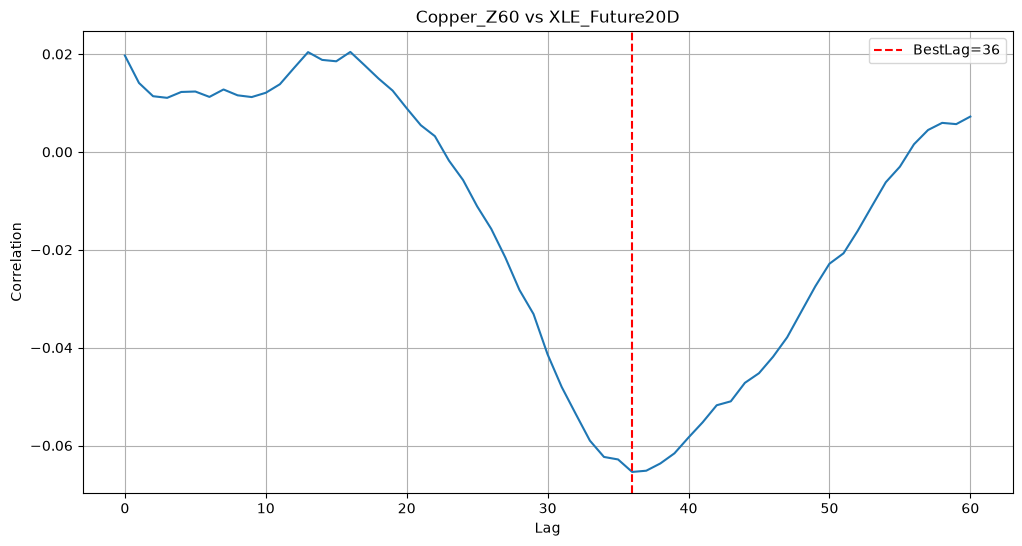

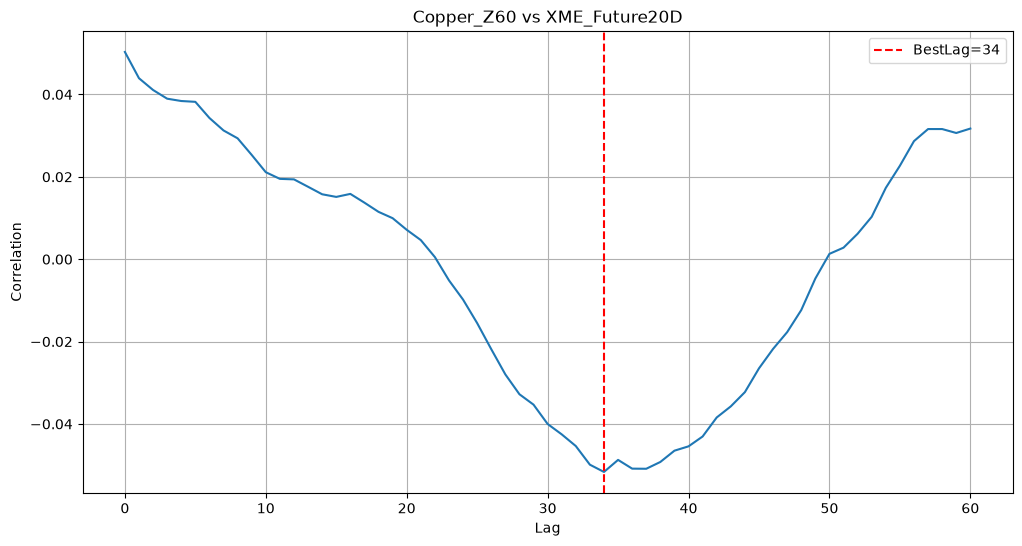

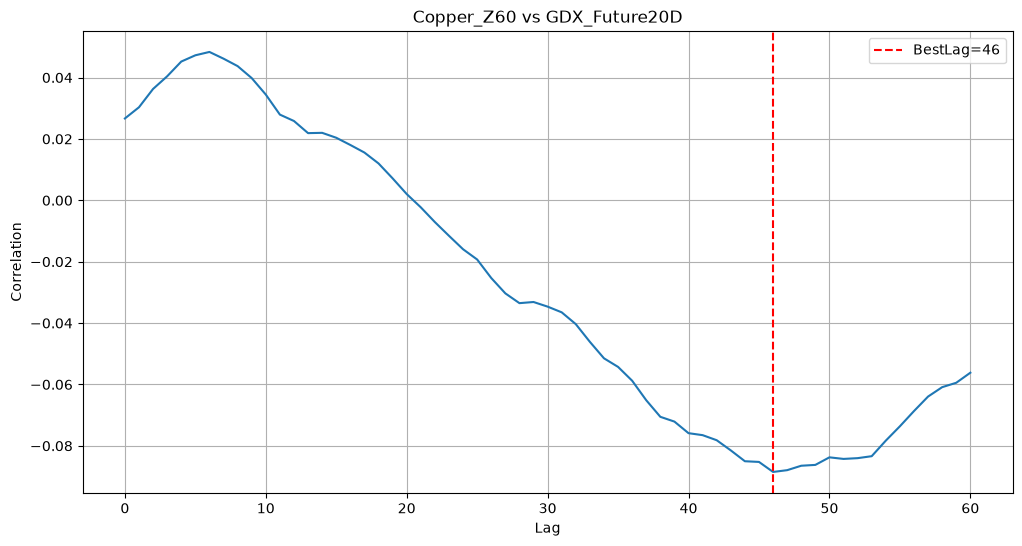

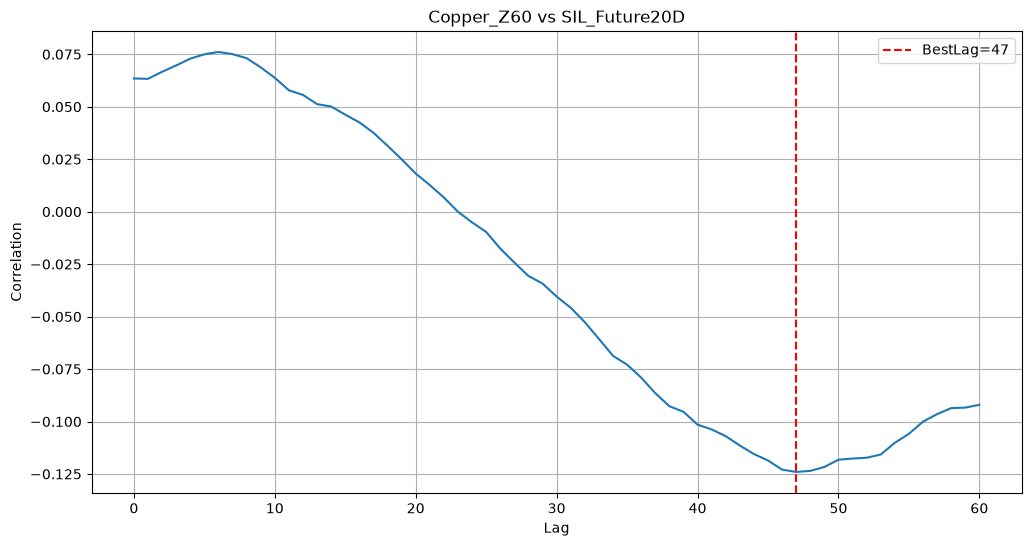

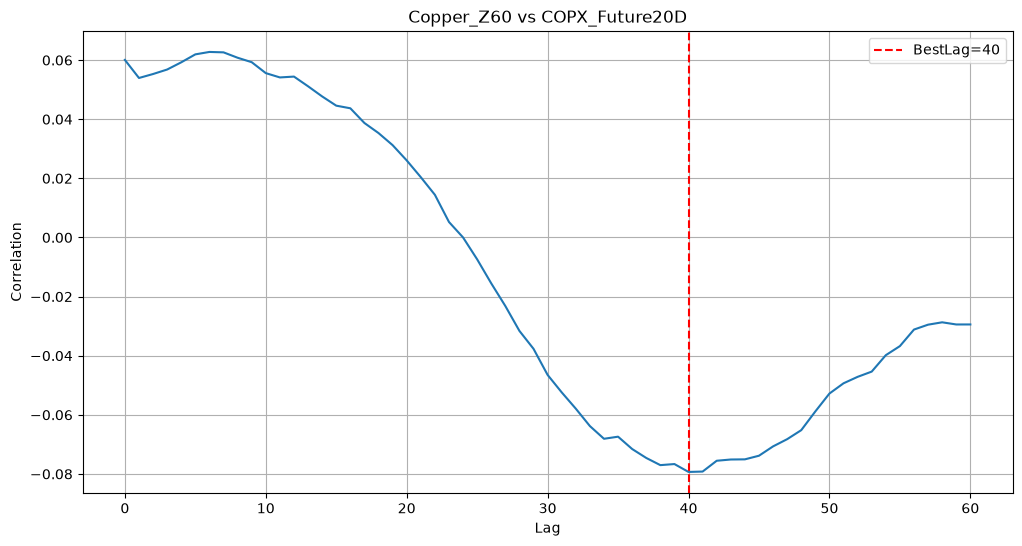

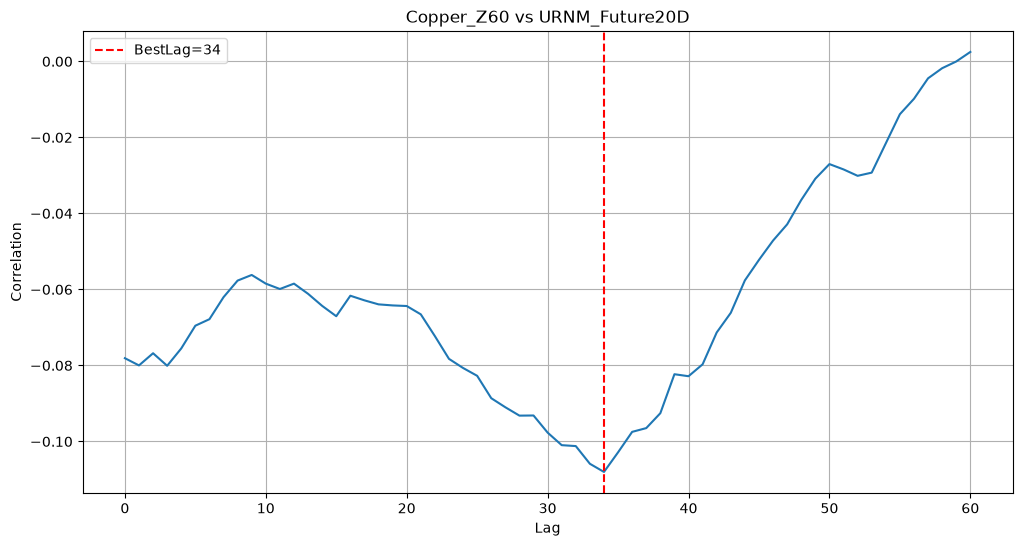

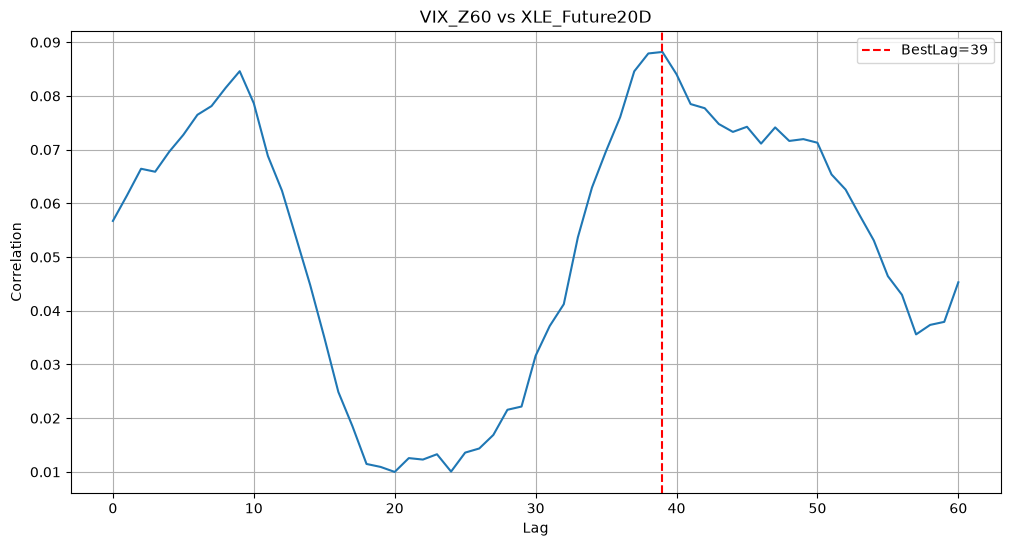

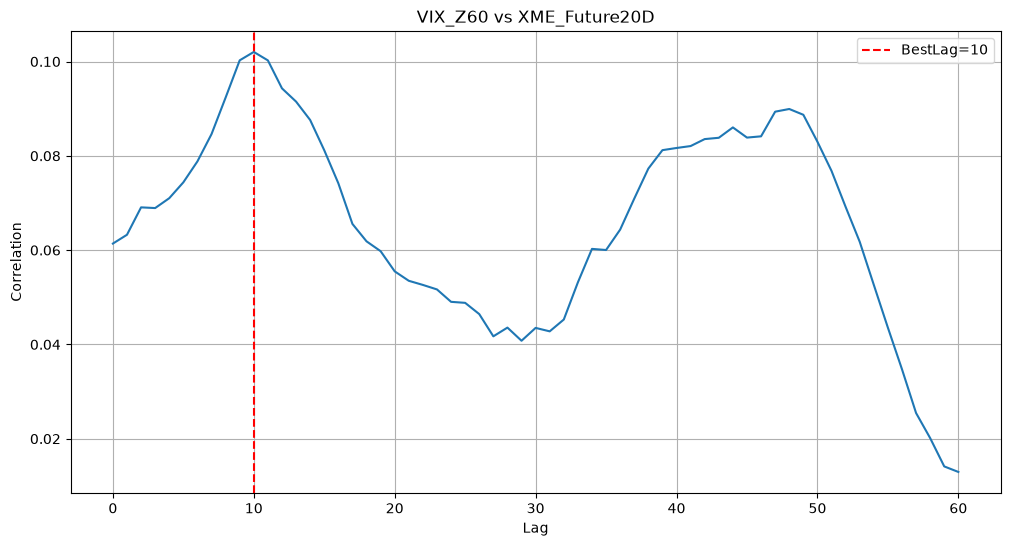

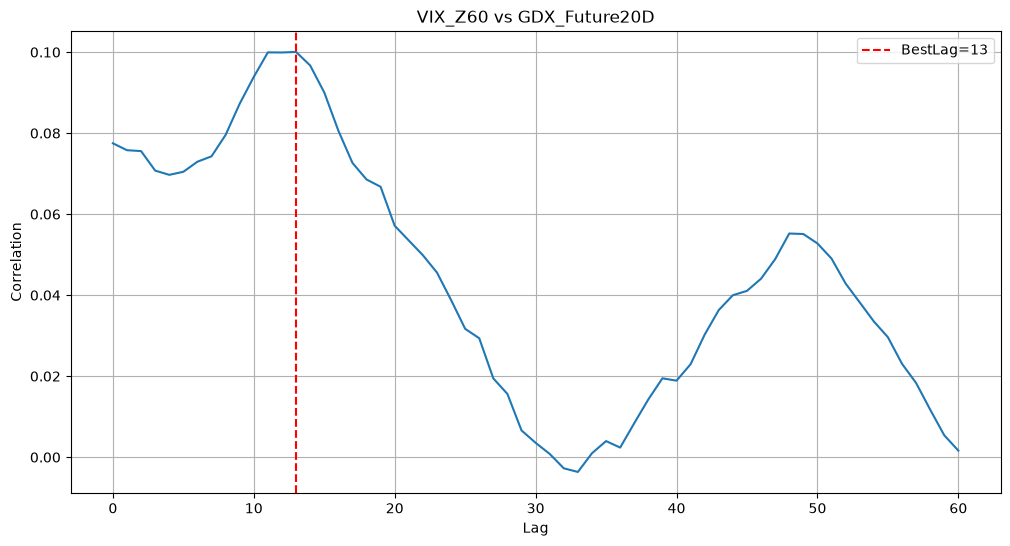

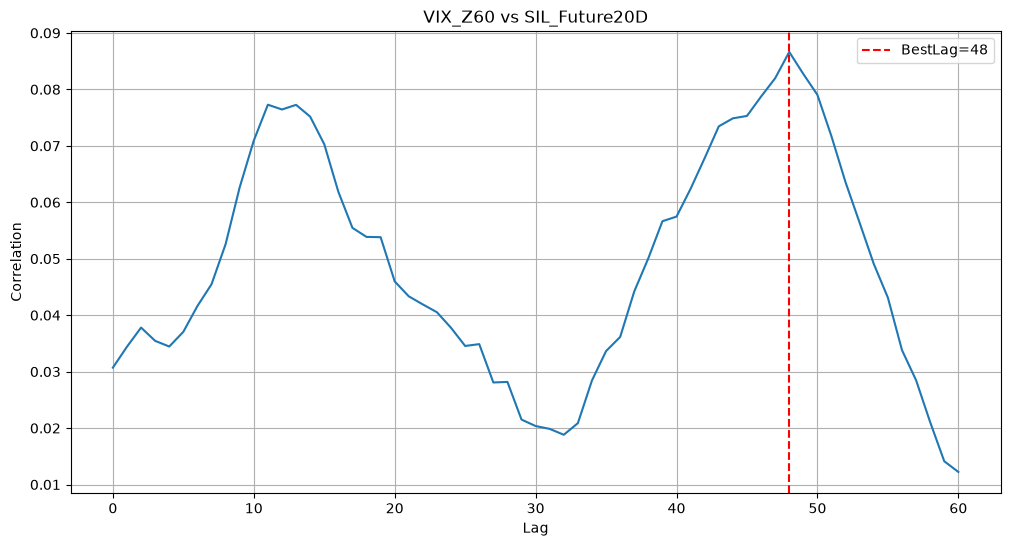

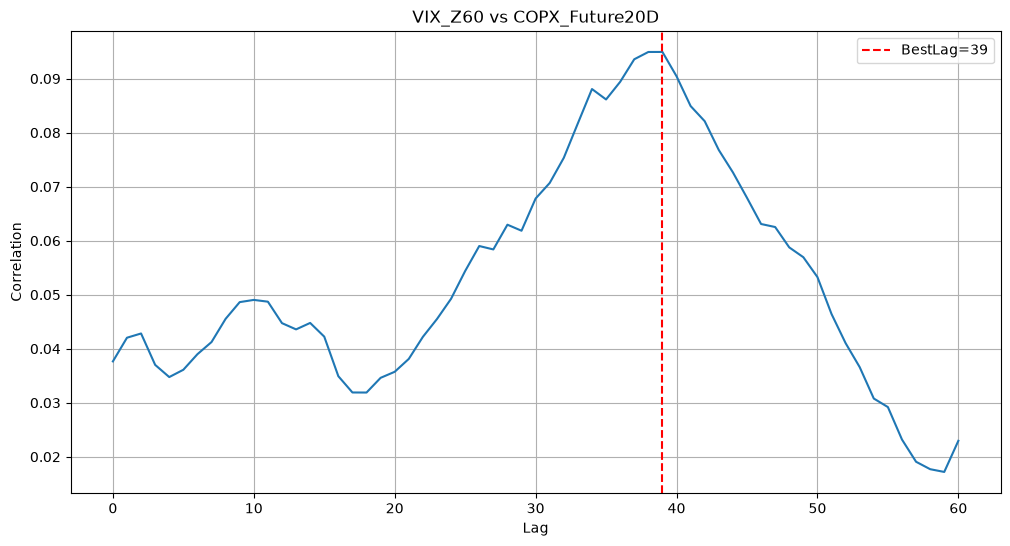

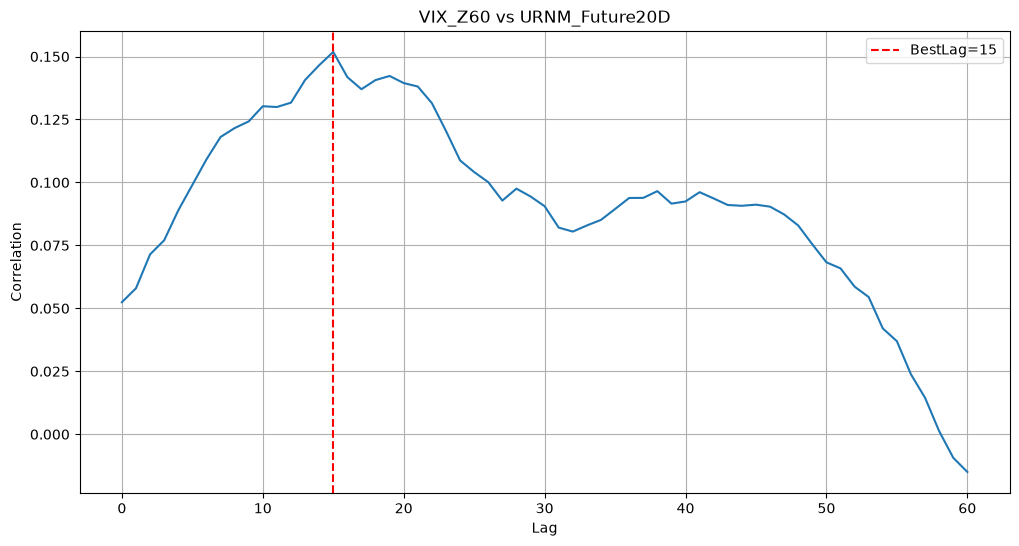

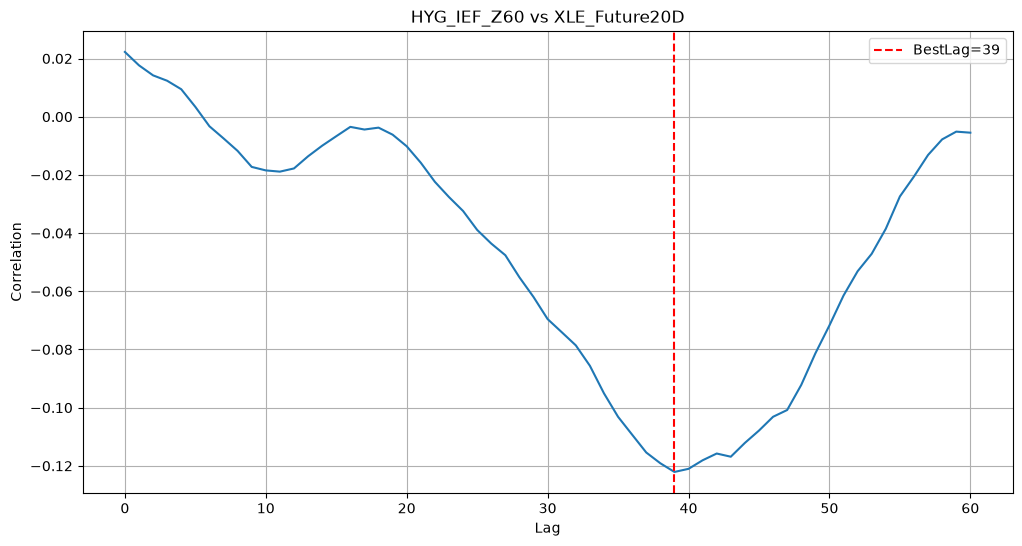

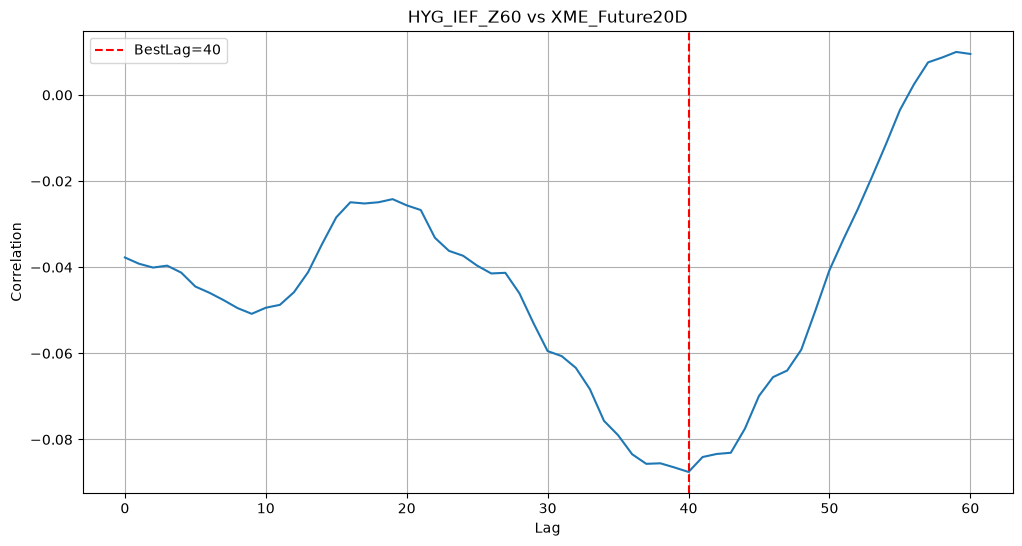

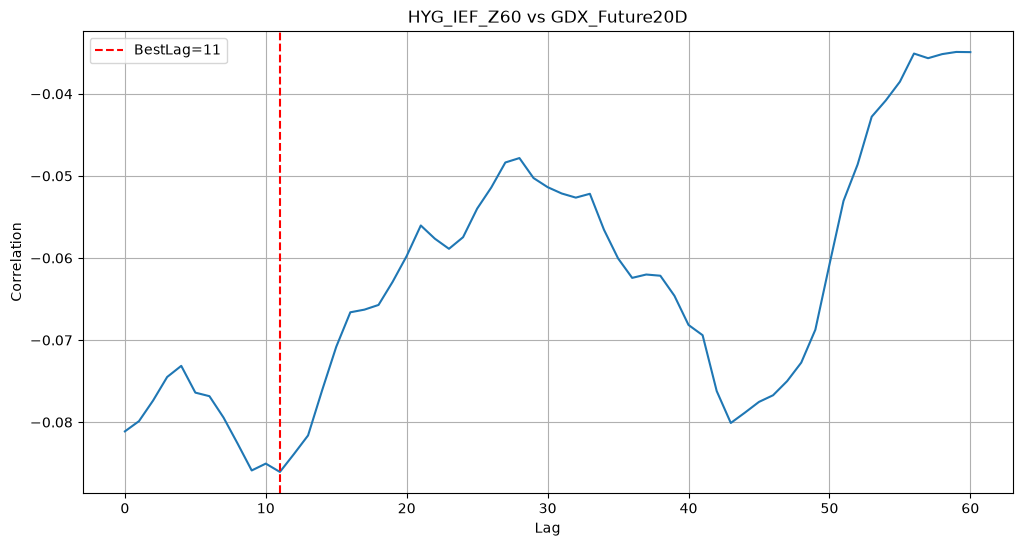

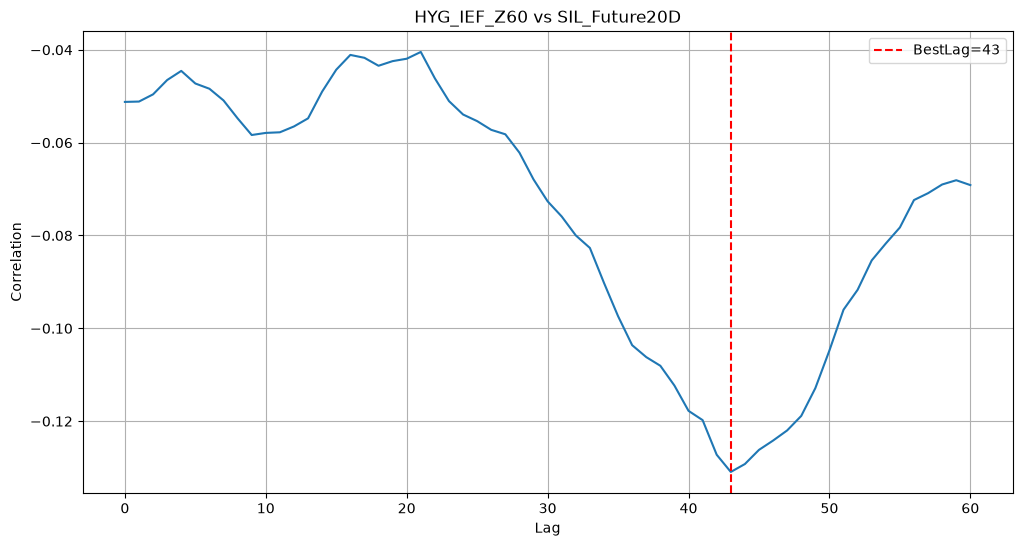

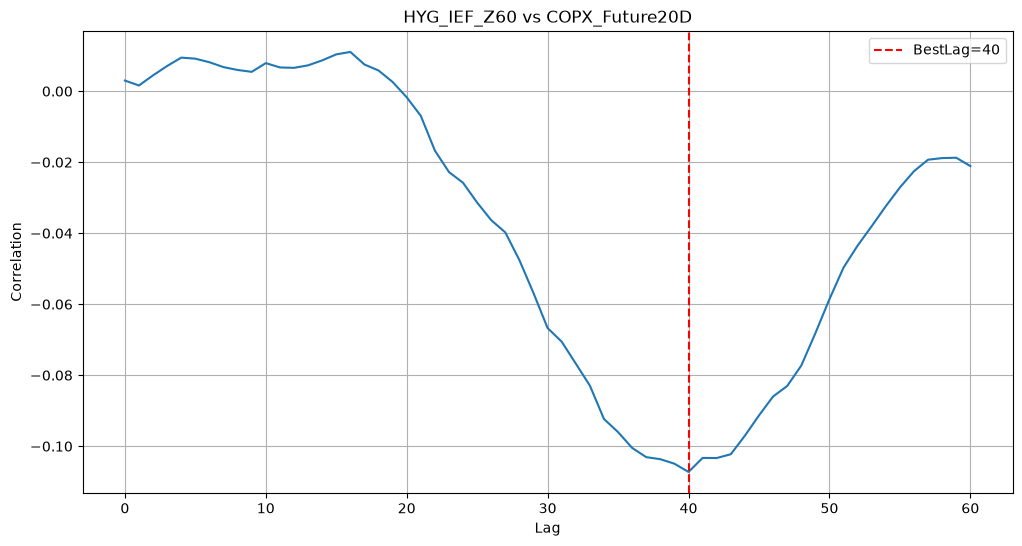

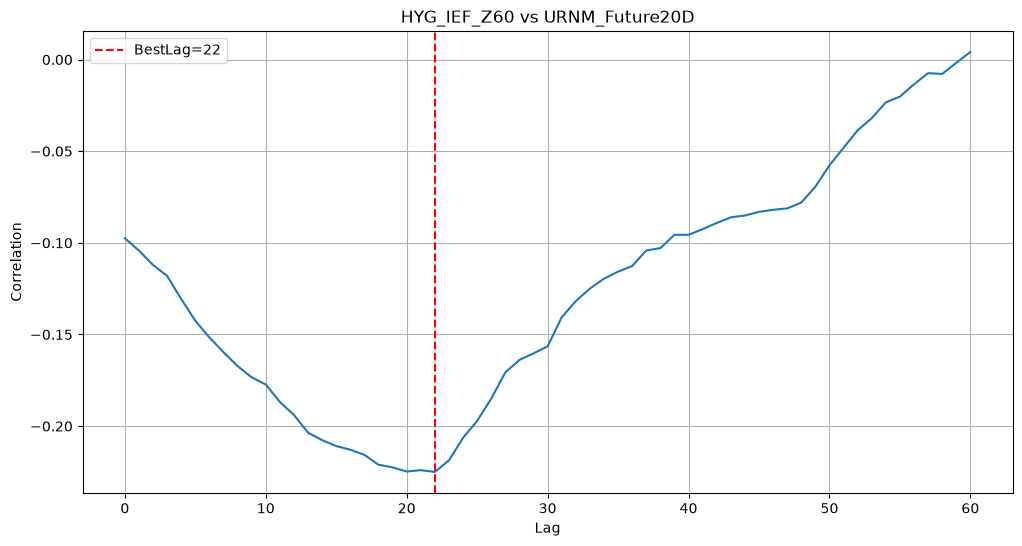

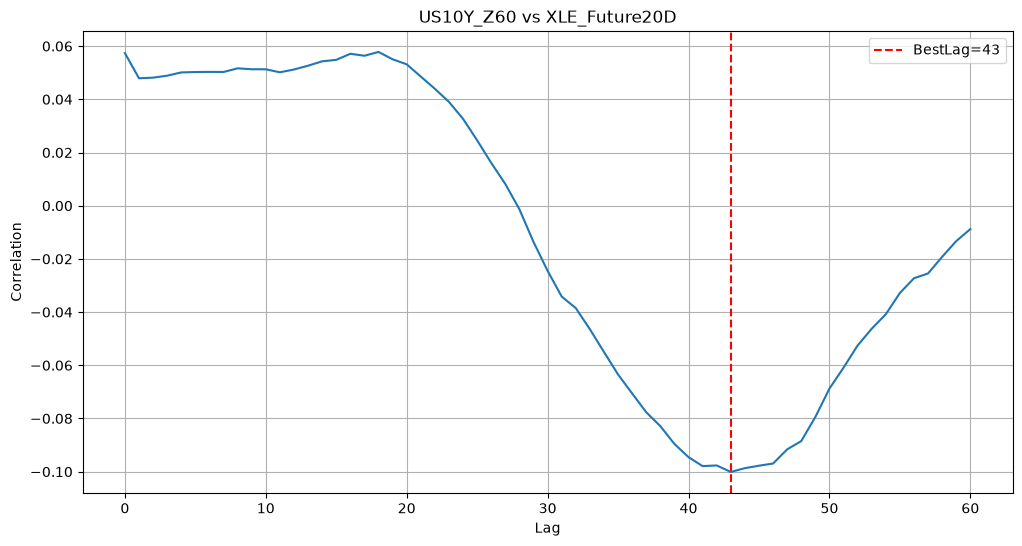

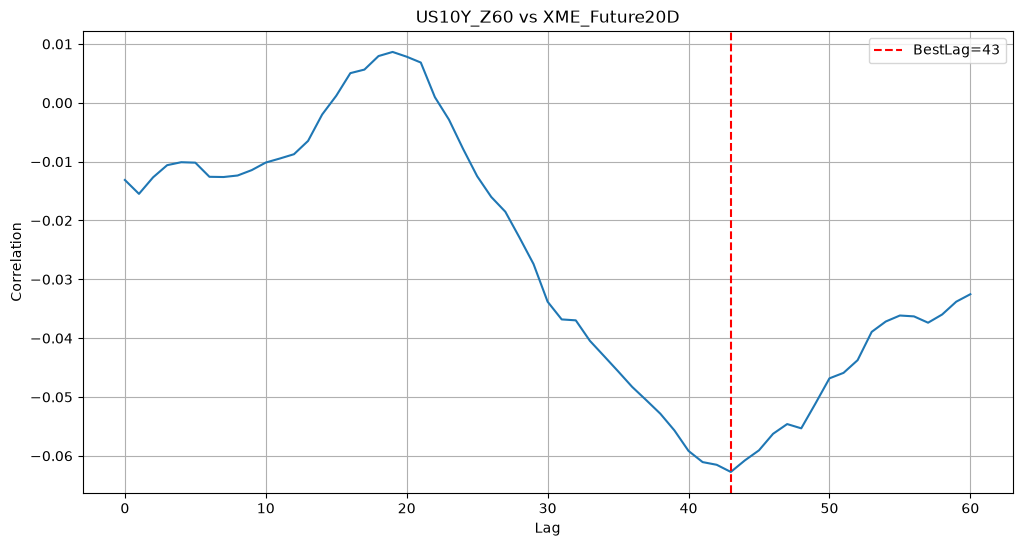

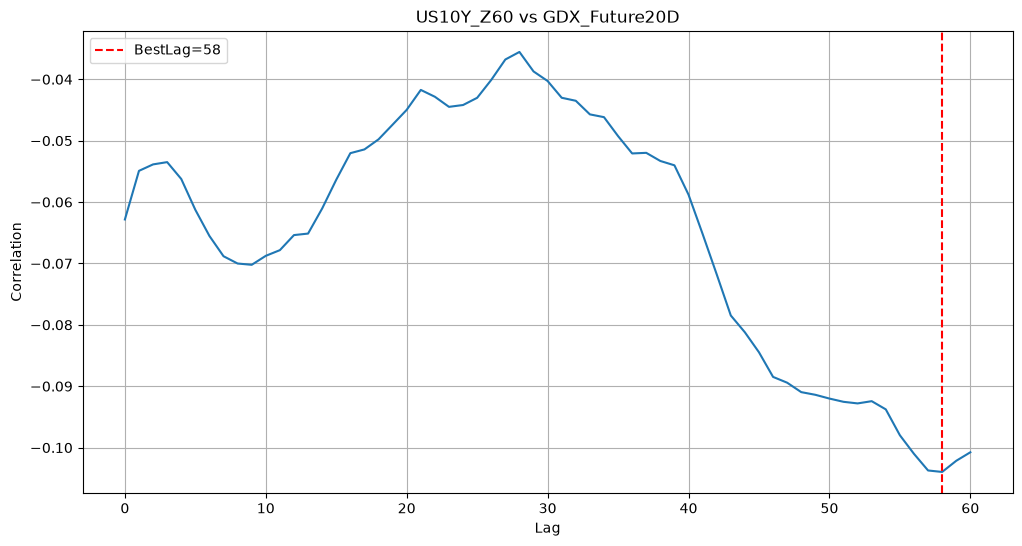

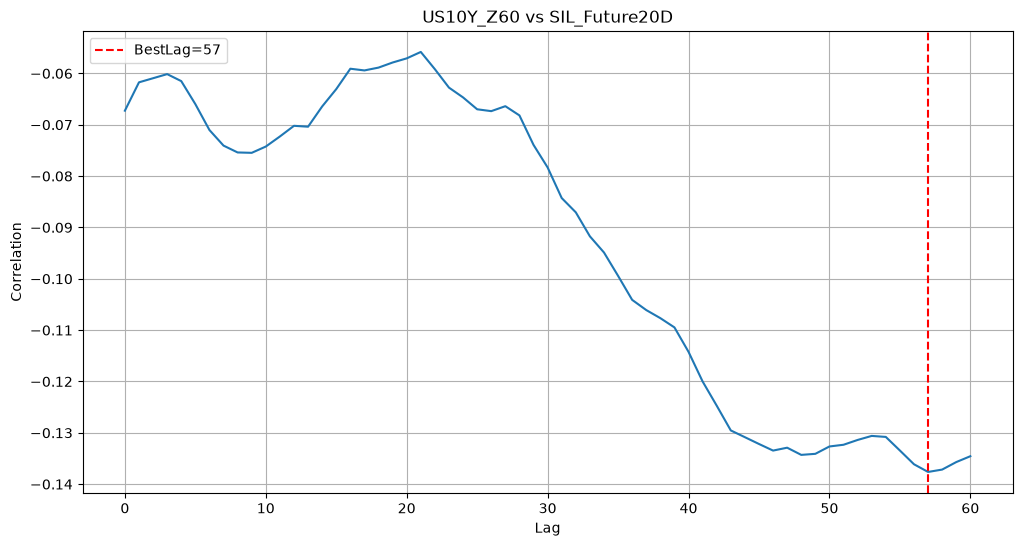

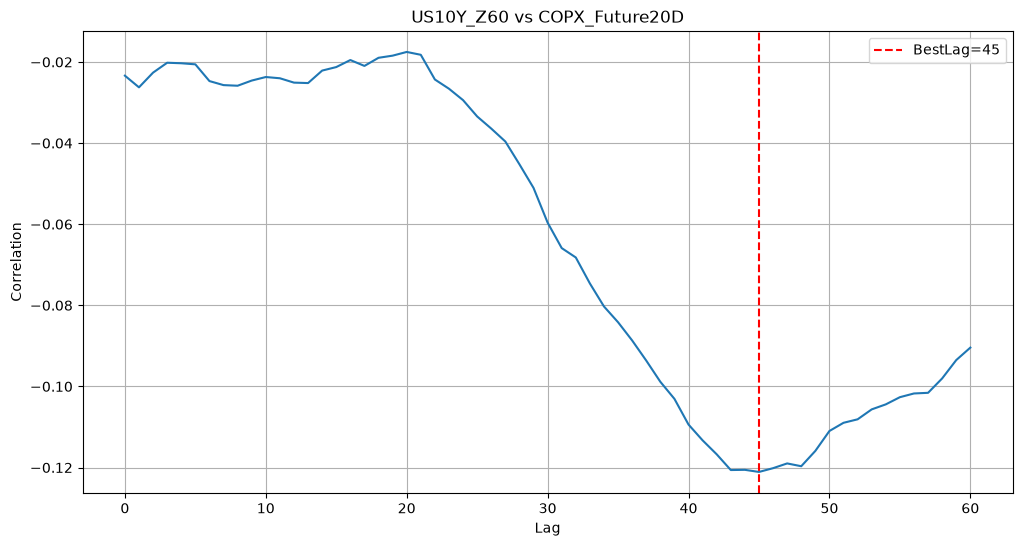

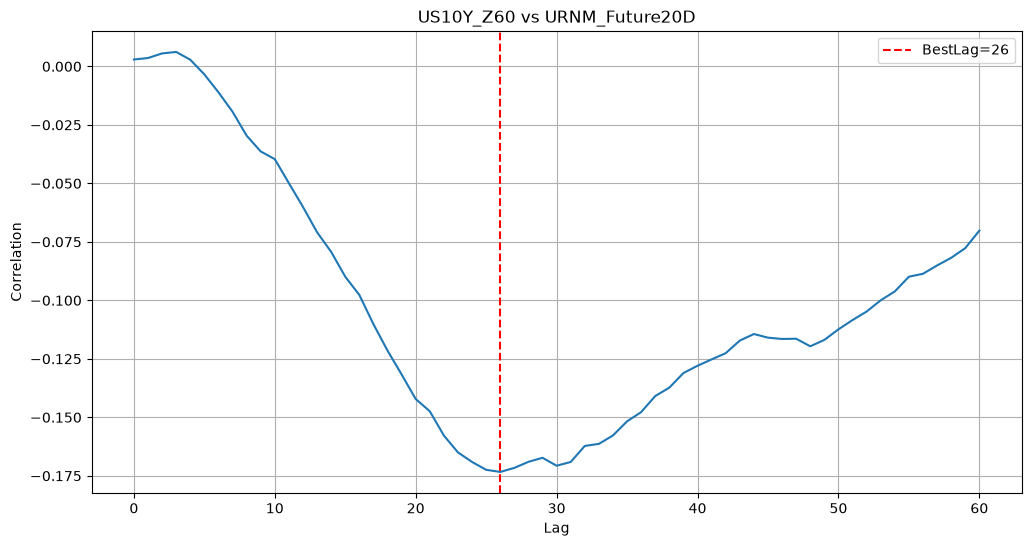

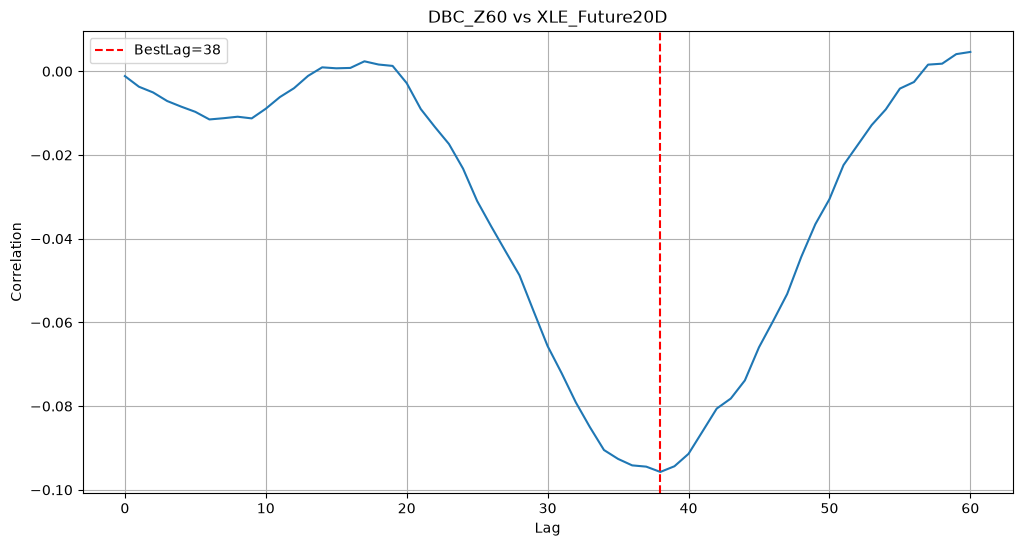

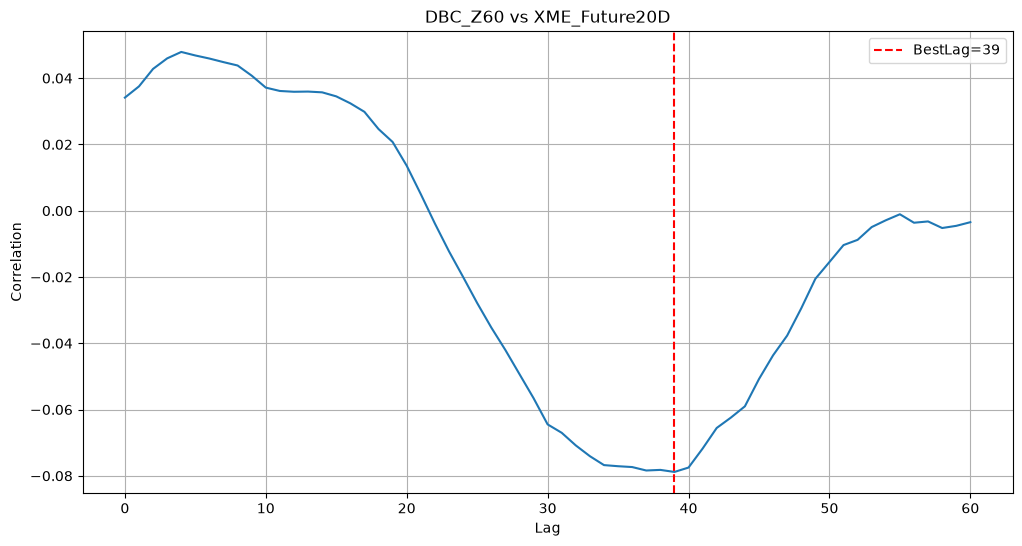

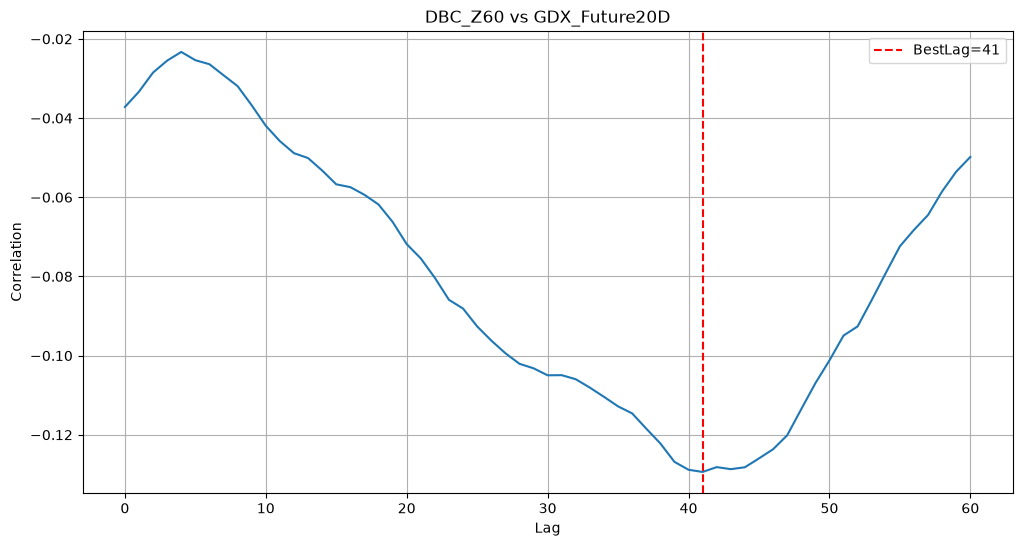

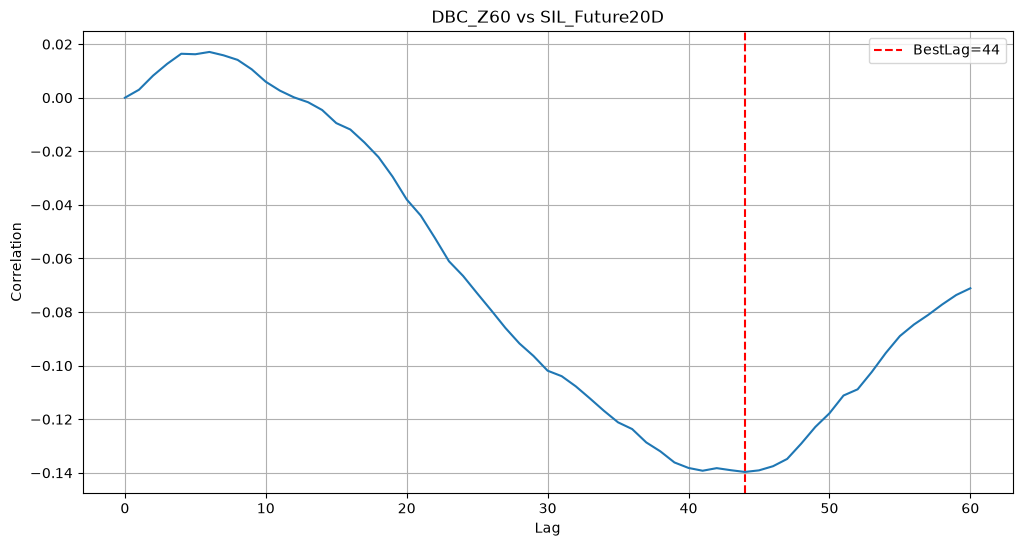

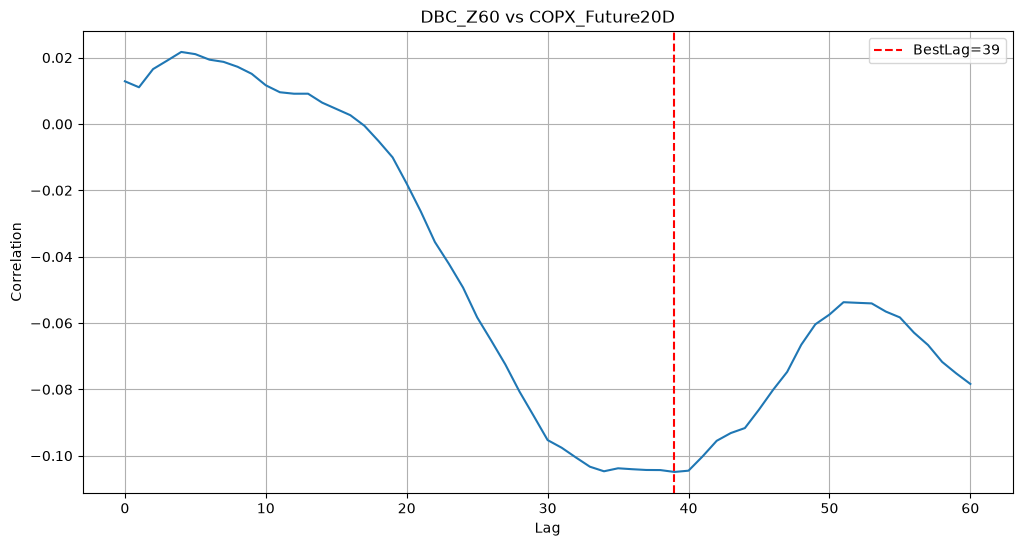

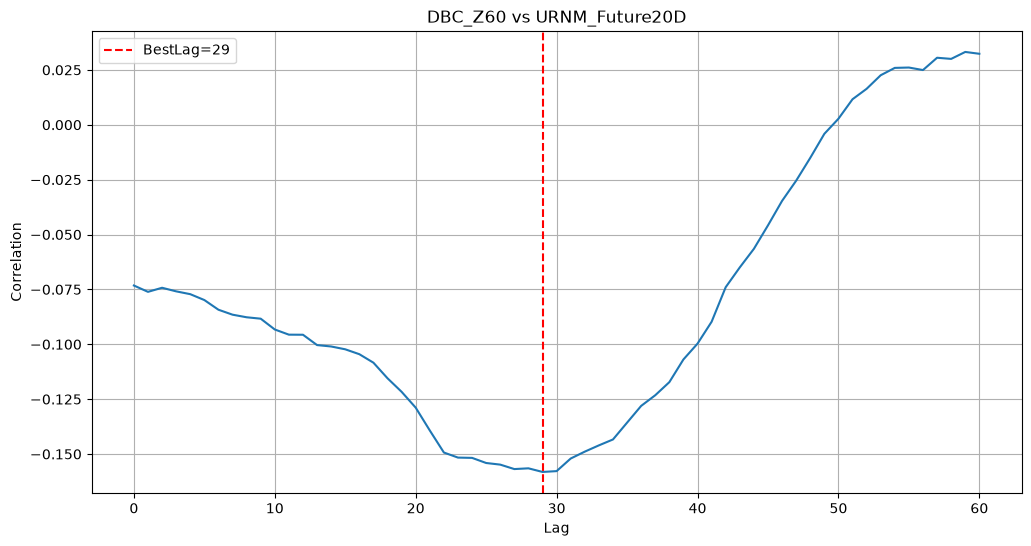

: 

In [ ]:
for feature in FEATURES:
    for target in TARGETS:
        # 対象のFeatureとTargetの結果を取得
        result = lead_lag_df[
            (lead_lag_df["Feature"] == feature)
            &
            (lead_lag_df["Target"] == target)
        ]
        # BestLagを取得
        best_lag = int(
            result["BestLag"].iloc[0]
        )
        # BestLagがNaNの場合はスキップ
        if pd.isna(best_lag):
            continue
        lag_corr = []
        # 各ラグに対する相関を計算
        for lag in LAGS:

            shifted_feature = (
                market_df[feature]
                .shift(lag)
            )

            temp = pd.concat(
                [
                    shifted_feature,
                    market_df[target]
                ],
                axis=1
            ).dropna()

            corr = temp.iloc[:, 0].corr(
                temp.iloc[:, 1]
            )

            lag_corr.append(corr)

        plt.figure(figsize=(12,6))

        plt.plot(
            list(LAGS),
            lag_corr
        )

        plt.axvline(
            best_lag,
            color="red",
            linestyle="--",
            label=f"BestLag={best_lag}"
        )

        plt.xlabel("Lag")
        plt.ylabel("Correlation")
        plt.title(
            f"{feature} vs {target}"
        )

        plt.legend()
        plt.grid(True)
        # ファイル名にコードと期間を含める
        output_path = output_dir / f"{feature}_VS_{target}__{start}_{end}.png"
        # 既存の画像ファイルが存在する場合は削除
        if output_path.exists():
            output_path.unlink()
        # 画像ファイルを保存
        fig = plt.gcf()
        fig.savefig(str(output_path), dpi=300, bbox_inches='tight')
        plt.show()
        plt.close(fig)

### 11. クロスコリレーション分析

### 12. 多変量分析

### 13. 特徴量重要度分析

### 14. Layer1スコア作成